# 04 | Avaliação do Modelo  In-Time vs. Out-of-Time (OOT)

Este notebook é a busca avaliar o modelo exportado em `02_Modelagem.ipynb` (`LGBM_Otimizado` + calibração isotônica + **threshold dinâmico por ticket**). Buscamos avaliar a estabilidade do modelo utilizando, dessa vez, a base **Out-of-Time** (`df_oot`, os 20% mais recentes). Ademais, avaliaremos como o drift no target e nas features impactam ao modelo.

> **Pergunta central:** o modelo continua **discriminando**, **decidindo** e **gerando lucro** em um período futuro que nunca viu? Onde ele perde força?

### Roteiro (storytelling)

| Seção | Pergunta de negócio | Análises |
|:---:|---|---|
| **1.0** | O que vamos avaliar? | Artefato, split temporal e escoragem — **In-Time = Treino (OOF) + Validação** |
| **2.0** | Quão bom é o modelo fora do tempo? | GINI, ROC-AUC, KS, PR-AUC, regra de decisão, resultado financeiro e matriz de confusão |
| **3.0** | A capacidade de ordenar risco se manteve? | Curvas ROC e Precision-Recall In-Time × OOT |
| **4.0** | Fraudes e legítimas continuam separadas? | KDE dos scores, KS (CDF) e escada de risco por decil |
| **5.0** | O modelo decide pelos motivos certos? | SHAP global, direção do impacto e estabilidade dos motores de decisão |
| **6.0** | O que mudou no mundo? | Target drift, PSI do score e PSI das features × importância SHAP |
| **7.0** | A performance é estável semana a semana? | GINI por semana ao longo de Treino → Validação → OOT |
| **8.0** | Onde o modelo falha? | Recall e prejuízo vazado por grupo/cluster de fraude (clusters ajustados no Treino e projetados no OOT) |
| **9.0** | Exportação e MLOps | Persistência das métricas de monitoramento contínuo e CSVs |


___
## 1.0 Configuração, Carga do Artefato e Escoragem

- Imports, resolução da raiz do projeto (local ou Colab) e funções dos módulos de `src/`

- Flags de execução para controlar processamento pesado e salvamento de figuras.

In [1]:
# ==============================================================================
# 1.0 CONFIGURAÇÃO DO AMBIENTE E IMPORTS
# ==============================================================================
import os
import sys
import json
import hashlib
import warnings
import importlib
from datetime import datetime
from pathlib import Path
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')

# Resolução robusta da raiz do projeto (Local e Colab) — mesmo padrão do 02_Modelagem
current_dir = Path(os.getcwd()).resolve()
if (current_dir / 'src').is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / 'src').is_dir():
    PROJECT_ROOT = current_dir.parent
elif (current_dir.parent.parent / 'src').is_dir():
    PROJECT_ROOT = current_dir.parent.parent
else:
    PROJECT_ROOT = current_dir

os.chdir(PROJECT_ROOT)
for p in [str(PROJECT_ROOT), os.path.abspath('.'), os.path.abspath('..')]:
    if p not in sys.path:
        sys.path.append(p)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import ks_2samp

# Funções do projeto: módulos de src/ (antes centralizados em utils.py)
from src.visualization.theme import (
    aplicar_estilo_azul,
    PALETA_AZUL,
    CMAP_AZUL,
)
from src.data.loader import (
    preparar_dados_modelagem,
)
from src.models.calibrate import (
    threshold_calibrado_para_bruto,
    gerar_scores_oof_treino,
)
from src.evaluation.metrics import (
    escorar_particao,
    adicionar_bloco_temporal,
    tabela_metricas_janelas,
    formatar_tabela_metricas,
    gerar_tabela_decis_ks,
    tabela_temporal,
    avaliar_modelo_por_grupo,
)
from src.evaluation.drift import (
    teste_qui_quadrado_temporal,
    calcular_psi_scores,
    relatorio_psi_features,
)
from src.evaluation.explainability import (
    calcular_shap_lgbm,
    ranking_shap,
)
from src.segmentation.fraud_clusters import (
    obter_rotulos_clusters_fraude,
)
from src.visualization.eval_plots import (
    plot_matrizes_confusao_janelas,
    plot_roc_pr_janelas,
    plot_kde_scores_janelas,
    plot_cdf_ks_janelas,
    plot_decis_janelas,
    plot_importancia_shap,
    plot_shap_beeswarm,
    plot_shap_janelas,
    plot_target_drift_temporal,
    plot_psi_score_faixas,
    plot_psi_vs_shap,
    plot_comparativo_psi_features,
    plot_gini_temporal,
    plot_recall_grupos_janelas,
    plot_score_fraudes_por_grupo,
    plot_matriz_prioridade_clusters,
    perfil_fn_vs_vp,
)

aplicar_estilo_azul()
pd.set_option('display.max_columns', 60)

# ------------------------------------------------------------------------------
# Flags e parâmetros da avaliação
# ------------------------------------------------------------------------------
USAR_OOF_TREINO = True      # True: Treino escorado Out-of-Fold (honesto) | False: in-sample (otimista, ~4x mais rápido)
N_AMOSTRA_SHAP  = 20_000    # amostra por janela para o TreeExplainer
DIAS_POR_BLOCO  = 7         # granularidade temporal (7 = semanal; 30 = mensal)
RANDOM_STATE    = 42

SALVAR_FIGURAS = True   # nome fixo em reports/figures/ (False = nome automático <função>__<título>)
DIR_FIGURAS = PROJECT_ROOT / 'reports' / 'figures'
DIR_METRICAS = PROJECT_ROOT / 'reports' / 'metrics'
DIR_METRICAS.mkdir(parents=True, exist_ok=True)

def fig_path(nome: str):
    # Caminho da figura quando SALVAR_FIGURAS = True (None = apenas exibe inline)
    return DIR_FIGURAS / nome if SALVAR_FIGURAS else None

print(f"Diretório raiz configurado: {PROJECT_ROOT}")
print("Funções de avaliação OOT importadas de src/ | estilo azul corporativo aplicado.")

Diretório raiz configurado: /content
Funções de avaliação OOT importadas de utils.py | estilo azul corporativo aplicado.


### 1.1 Carga da Master Table e do Artefato Final

- O artefato `modelo_fraude_final.joblib` (Seção 8.3 do `02_Modelagem`) contém os dados para a **inferência**.

- **Modelo treinado em 100% do Treino,** calibrador isotônico, lista de features e os parâmetros da regra dinâmica:

$$\text{bloquear se } p_{cal} \geq t_{min} + (t_{max} - t_{min}) \cdot e^{-k \cdot \text{Valor US\$}}$$

In [2]:
# ==============================================================================
# 1.1 CARGA DA MASTER TABLE, METADADOS E ARTEFATO DO MODELO FINAL
# ==============================================================================
dir_dados = PROJECT_ROOT / 'data' / 'processed'
dir_artifacts = PROJECT_ROOT / 'artifacts'

caminhos = {
    'master':   dir_dados / 'df_master.parquet',
    'meta':     dir_dados / 'features_metadata.json',
    'artefato': dir_artifacts / 'modelo_fraude_final.joblib',
    'metadata': dir_artifacts / 'modelo_fraude_final_metadata.json',
    'metrics':  dir_artifacts / 'modelo_fraude_final_metrics.json',
}
faltantes = [k for k, c in caminhos.items() if not c.exists()]
if faltantes:
    raise FileNotFoundError(
        f"Arquivos não encontrados: {faltantes}. Execute 01_EDA.ipynb (df_master) e 02_Modelagem.ipynb (Seção 8.3) antes."
    )

df_master = pd.read_parquet(caminhos['master'])
with open(caminhos['meta'], 'r', encoding='utf-8') as f:
    meta = json.load(f)

artefato = joblib.load(caminhos['artefato'])
with open(caminhos['metadata'], 'r', encoding='utf-8') as f:
    modelo_metadata = json.load(f)
with open(caminhos['metrics'], 'r', encoding='utf-8') as f:
    modelo_metrics = json.load(f)

FEATURES = artefato['features']
REGRA = artefato['regra_decisao']
hash_artefato = hashlib.md5(caminhos['artefato'].read_bytes()).hexdigest()[:8]

print('=' * 78)
print(f" Master Table        : {df_master.shape[0]:,} transações x {df_master.shape[1]} colunas")
print(f" Modelo              : {artefato['nome_modelo']} ({modelo_metadata.get('classe', '-')}) | hash {hash_artefato}")
print(f" Features            : {len(FEATURES)}")
print(f" Calibração          : {modelo_metadata.get('calibracao', '-')}")
print(f" Regra de decisão    : bloquear se p_cal >= {REGRA['t_min']:.4f} + ({REGRA['t_max']:.4f} - {REGRA['t_min']:.4f})"
      f" · exp(-{REGRA['k']:.5f} · Valor US$)")
print(f" Threshold fixo ref. : {REGRA.get('threshold_fixo_referencia')}")
print('=' * 78)

 Master Table        : 590,540 transações x 152 colunas
 Modelo              : LGBM_Otimizado (lightgbm.sklearn.LGBMClassifier) | hash ed595960
 Features            : 30
 Calibração          : IsotonicRegression (ajustada no OOF do Treino)
 Regra de decisão    : bloquear se p_cal >= 0.0258 + (0.0513 - 0.0258) · exp(-0.00492 · Valor US$)
 Threshold fixo ref. : 0.03408815351288434


### 1.2 Reconstrução do Split Temporal e Definição das Janelas

- O split é reconstruído com **a mesma função e proporções** do `02_Modelagem` (`preparar_dados_modelagem`, 60/20/20 por `TransactionDT`) 

- As agregações, frequency encodings e o ordinal encoding continuam ajustados **somente no Treino**, então o OOT recebe exatamente as transformações que receberia em produção.

| Janela | Composição | Papel |
|---|---|---|
| **In-Time** | Treino (60%) + Validação (20%) | Referência: o período que o modelo "conhece" |
| **Out-of-Time** | OOT (20% finais) | Teste cego: o futuro |



In [3]:
# ==============================================================================
# 1.2 SPLIT TEMPORAL (MESMA ESTEIRA DO 02_MODELAGEM) — IN-TIME x OOT
# ==============================================================================
dados_prep = preparar_dados_modelagem(df_master=df_master, meta=meta, train_ratio=0.60, test_ratio=0.20)

X_train, y_train = dados_prep['X_train'], dados_prep['y_train']
X_val,   y_val   = dados_prep['X_test'],  dados_prep['y_test']
X_oot,   y_oot   = dados_prep['X_oot'],   dados_prep['y_oot']
train_df, df_validacao, oot_df = dados_prep['train_df'], dados_prep['test_df'], dados_prep['oot_df']
grupos_mes = dados_prep['grupos_mes']

# Sanidade: todas as features do artefato precisam existir após a engenharia pós-split
features_ausentes = [f for f in FEATURES if f not in X_oot.columns]
assert not features_ausentes, f"Features do artefato ausentes no OOT: {features_ausentes}"

# Matriz In-Time (Treino + Validação) com as features do modelo — usada em SHAP e PSI
X_in_time = pd.concat([X_train[FEATURES], X_val[FEATURES]])
X_oot_m = X_oot[FEATURES]

dia = lambda df: df['TransactionDT'] / 86400
print(f"\nPeríodo In-Time : dia {dia(train_df).min():.0f} → {dia(df_validacao).max():.0f}")
print(f"Período OOT     : dia {dia(oot_df).min():.0f} → {dia(oot_df).max():.0f}")

-----------------------------------------------------------------
X_train shape (60%): (354324, 150) | Taxa de Fraude: 3.38%
X_test  shape (20%): (118108, 150)  | Taxa de Fraude: 3.90%
X_oot   shape (20%): (118108, 150)  | Taxa de Fraude: 3.44%  [BLINDADO P/ AVALIAÇÃO FINAL]
Total de features preditoras: 150
Features lineares (LR): 46
Taxa de desbalanceamento (Treino): 28.56:1
Blocos mensais no Treino (GroupKFold): [0, 1, 2, 3] (Total: 4 meses)
-----------------------------------------------------------------

Período In-Time : dia 1 → 141
Período OOT     : dia 141 → 183


### 1.3 Score das Partições

- Cada transação recebe: probabilidade **bruta** (usada nas métricas de ranqueamento, como no `02`), probabilidade **calibrada**, o **corte dinâmico** do seu ticket e a **decisão** (bloquear/aprovar). 

- Também é criado o bloco temporal (`semana`) para as análises de estabilidade temporal do modelo.

In [4]:
# ==============================================================================
# 1.3 SCORE: TREINO (OOF) + VALIDAÇÃO + OOT COM O ARTEFATO CONGELADO
# ==============================================================================
if USAR_OOF_TREINO:
    print("[INFO] Gerando scores Out-of-Fold do Treino (GroupKFold mensal, hiperparâmetros do artefato)...")
    prob_raw_treino = gerar_scores_oof_treino(artefato, X_train, y_train, groups=grupos_mes, n_splits=4)
    rotulo_treino = 'Treino (OOF)'
else:
    print("[AVISO] USAR_OOF_TREINO = False → Treino escorado in-sample: métricas In-Time ficarão OTIMISTAS.")
    prob_raw_treino = None
    rotulo_treino = 'Treino (OOF)'  # rótulo mantido para os gráficos; interprete como in-sample

df_scores = pd.concat([
    escorar_particao(artefato, X_train, train_df, rotulo_treino, 'In-Time', prob_raw=prob_raw_treino),
    escorar_particao(artefato, X_val, df_validacao, 'Validação', 'In-Time'),
    escorar_particao(artefato, X_oot, oot_df, 'OOT', 'OOT'),
])
df_scores = adicionar_bloco_temporal(df_scores, dt_inicio=df_master['TransactionDT'].min(),
                                     dias_por_bloco=DIAS_POR_BLOCO, nome_coluna='semana')

base_treino = df_scores[df_scores['Particao'] == rotulo_treino]
base_val    = df_scores[df_scores['Particao'] == 'Validação']
base_it     = df_scores[df_scores['Janela'] == 'In-Time']
base_oot    = df_scores[df_scores['Janela'] == 'OOT']

# Faixa do corte dinâmico convertida para a escala da probabilidade BRUTA (usada nos gráficos de score)
FAIXA_CORTE_RAW = (
    threshold_calibrado_para_bruto(artefato['calibrador'], REGRA['t_min']),
    threshold_calibrado_para_bruto(artefato['calibrador'], REGRA['t_max']),
)

resumo = df_scores.groupby('Particao', sort=False).agg(
    Transacoes=('isFraud', 'size'),
    Taxa_Fraude=('isFraud', 'mean'),
    Prob_Calibrada_Media=('prob_cal', 'mean'),
    Ticket_Medio_USD=('amt_usd', 'mean'),
    Pct_Bloqueado=('bloquear', 'mean'),
)
resumo['Erro_Calibracao_Rel'] = resumo['Prob_Calibrada_Media'] / resumo['Taxa_Fraude'] - 1
display(resumo.style.format({
    'Transacoes': '{:,.0f}', 'Taxa_Fraude': '{:.2%}', 'Prob_Calibrada_Media': '{:.2%}',
    'Ticket_Medio_USD': '$ {:,.2f}', 'Pct_Bloqueado': '{:.2%}', 'Erro_Calibracao_Rel': '{:+.1%}',
}).set_properties(subset=pd.IndexSlice[['OOT'], :], **{'background-color': PALETA_AZUL['gelo'], 'color': '#000000', 'font-weight': 'bold'}))
print(f"Faixa do corte dinâmico na escala bruta: [{FAIXA_CORTE_RAW[0]:.4f} (alto ticket) – {FAIXA_CORTE_RAW[1]:.4f} (micro-compra)]")

[INFO] Gerando scores Out-of-Fold do Treino (GroupKFold mensal, hiperparâmetros do artefato)...
  [OOF] fold 1/4 concluído | 130,968 transações escoradas
  [OOF] fold 2/4 concluído | 91,768 transações escoradas
  [OOF] fold 3/4 concluído | 89,838 transações escoradas
  [OOF] fold 4/4 concluído | 41,750 transações escoradas


,Transacoes,Taxa_Fraude,Prob_Calibrada_Media,Ticket_Medio_USD,Pct_Bloqueado,Erro_Calibracao_Rel
Particao,,,,,,
Treino (OOF),"354,324",3.38%,3.38%,$ 134.32,15.71%,+0.0%
Validação,"118,108",3.90%,3.09%,$ 134.63,14.06%,-20.8%
OOT,"118,108",3.44%,2.94%,$ 137.53,14.28%,-14.6%


Faixa do corte dinâmico na escala bruta: [0.3529 (alto ticket) – 0.5149 (micro-compra)]



> **Análise de Resultados (Score das Partições)**
> 
> *   **Target Drift (`Taxa_Fraude`):** Observa-se uma **variação pequena na taxa de fraude no OOT** (`3,44%`, contra `3,90%` na Validação e `3,38%` no Treino); o gráfico temporal (Seção 6.1) detalha a evolução semanal.
>
> *   **Calibração (`Erro_Calibracao_Rel`):** O Treino aparece com erro zero porque o calibrador isotônico foi ajustado no próprio OOF. Fora dele, o modelo **subestima** a fraude: `-20,8%` na Validação e `-14,6%` no OOT.
>
> *   **Impacto Operacional (`Pct_Bloqueado`):** O percentual de bloqueios no OOT (`14,28%`) fica entre a Validação (`14,06%`) e o Treino (`15,71%`): **não há aumento relevante** do volume enviado para bloqueio/revisão.


---
## 2.0 Performance Global  Treino (OOF) · Validação · In-Time · OOT

Métricas organizadas em três blocos, todas calculadas **uma única vez** tendo como base o modelo otimizado.

| Bloco | Métricas | O que respondem |
|---|---|---|
| **Ranqueamento** (prob. bruta) | ROC-AUC, **GINI** = 2·AUC − 1, **KS**, PR-AUC | O modelo ordena fraude acima de legítima? (independe do corte) |
| **Regra de decisão** (threshold dinâmico) | Precision, Recall, F1, Aprovação, Aceitação | O corte de produção continua bem calibrado? |
| **Financeiro** (US$) | Chargeback FN, Lucro Líquido, Lucro/Transação, Margem | O modelo continua gerando valor? |


In [5]:
# ==============================================================================
# 2.0 RELATÓRIO DE MÉTRICAS POR JANELA (SEM CROSS-VALIDATION)
# ==============================================================================
bases_avaliacao = {
    rotulo_treino: base_treino,
    'Validação':   base_val,
    'In-Time':     base_it,
    'OOT':         base_oot,
}
df_metricas = tabela_metricas_janelas(bases_avaliacao, ref='In-Time', alvo='OOT')
display(formatar_tabela_metricas(df_metricas, destacar='OOT'))

df_metricas.to_csv(DIR_METRICAS / 'avaliacao_metricas_in_time_vs_oot.csv')
m_it, m_oot = df_metricas['In-Time'], df_metricas['OOT']
print(f"[RESUMO] GINI: {m_it['GINI']:.4f} → {m_oot['GINI']:.4f} ({(m_oot['GINI'] / m_it['GINI'] - 1) * 100:+.1f}%) | "
      f"KS: {m_it['KS']:.4f} → {m_oot['KS']:.4f} | Recall: {m_it['Recall']:.1%} → {m_oot['Recall']:.1%} | "
      f"Lucro/tx: $ {m_it['Lucro por Transação']:.3f} → $ {m_oot['Lucro por Transação']:.3f}")

,Treino (OOF),Validação,In-Time,OOT,Δ (OOT − In-Time)
Métrica,,,,,
Transações,"354,324","118,108","472,432","118,108",—
Taxa de Fraude,3.38%,3.90%,3.51%,3.44%,-0.07 p.p.
ROC-AUC,0.8890,0.9047,0.8930,0.8736,-0.0194
GINI,0.7780,0.8094,0.7859,0.7472,-0.0388
KS,0.6181,0.6482,0.6246,0.5773,-0.0474
PR-AUC,0.4190,0.5099,0.4401,0.4204,-0.0197
Precision,16.18%,20.83%,17.24%,16.38%,-0.87 p.p.
Recall,75.13%,75.02%,75.10%,67.96%,-7.14 p.p.
F1-Score,0.2662,0.3260,0.2805,0.2639,-0.0166


[RESUMO] GINI: 0.7859 → 0.7472 (-4.9%) | KS: 0.6246 → 0.5773 | Recall: 75.1% → 68.0% | Lucro/tx: $ 0.556 → $ 0.304


> **Insights da Avaliação Out-of-Time (OOT)**
>
> *   **Leve Degradação do Ranqueamento:** O modelo `manteve a robustez temporal`, mas apresentou uma queda no poder de ranqueamento no OOT (ROC-AUC de `0,893` para `0,874`; GINI de `0,786` para `0,747`). Contra a Validação isolada (GINI `0,809`), a queda é maior (`-0,062`), então há **perda real de discriminação**, e não só efeito de calibração.
>
> *   **Recall:** O Recall caiu de **`75,1%` (In-Time) / `75,0%` (Validação) para `68,0%` (OOT)**. A sub-calibração não explica sozinha essa queda: o erro de calibração na Validação (`-20,8%`) era maior que no OOT (`-14,6%`) e, mesmo assim, o Recall da Validação ficou em `75,0%`. A queda acompanha a perda de GINI e se concentra no grupo *Cartão Clonado* (Seção 8).
>
> *   **Experiência do Cliente:** A **Aprovação de Legítimas subiu para `87,63%`** no OOT (contra `86,88%` no In-Time), e a aceitação geral para `85,72%`. `O atrito com o cliente bom diminuiu levemente.`
>
> *   **Viabilidade Financeira Mantida:** O lucro por transação no OOT (`$ 0,304`) é **maior** que o da Validação (`$ 0,236`), embora menor que o do In-Time (`$ 0,556`, inflado pelo OOF do Treino, onde calibrador e threshold foram ajustados). A operação lucra `+US$ 35,9 mil` no OOT, revertendo um prejuízo que seria de **- US$ 297,3 mil** sem modelo.
>
> *   **Volume Operacional Estável:** A taxa de bloqueio geral (`Pct_Bloqueado`) ficou em **`14,28%` no OOT**, entre a Validação e o Treino, mostrando que a regra dinâmica não causou `aumento demasiado de bloqueios e o time de análise não será sobrecarregado.`

### 2.1 Matriz de Confusão — In-Time vs. OOT

Decisão final do threshold dinâmico. Percentuais **sobre a classe real** (cada linha soma 100%):

- **VN:**  legítima aprovada (receita +2%) || **FP:**  legítima bloqueada (atrito e −2%)
- **FN:**  fraude aprovada (chargeback −100%) || **VP:**  fraude barrada (prejuízo evitado)

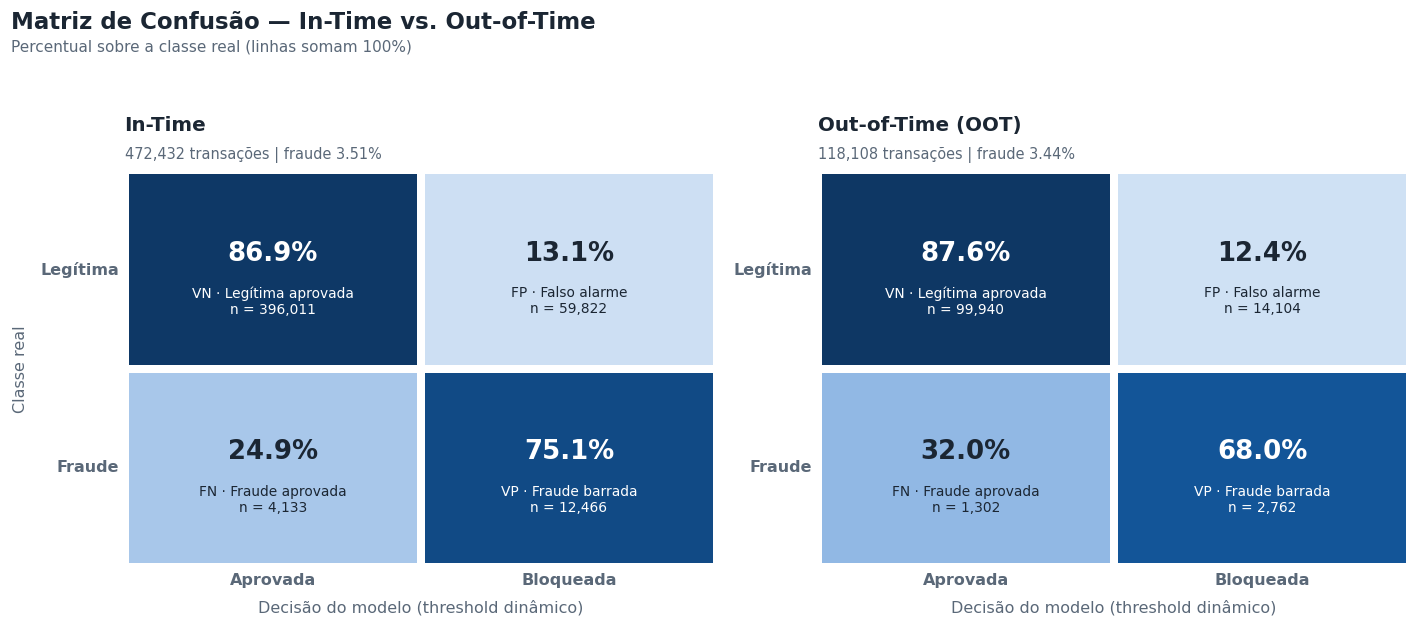

In [6]:
# ==============================================================================
# 2.1 MATRIZES DE CONFUSÃO LADO A LADO (REGRA DINÂMICA)
# ==============================================================================
df_cm = plot_matrizes_confusao_janelas({'In-Time': base_it, 'Out-of-Time (OOT)': base_oot},
                                       filepath=fig_path('04_01_matriz_confusao_in_time_vs_oot.png'))
display(df_cm.style.format({'Transações': '{:,.0f}', '% da Classe': '{:.2%}'}))

> **Análise de Resultados — Performance Global**
>
> *   **Ranqueamento (GINI/KS):** O modelo apresentou uma degradação temporal moderada. O GINI caiu de `0,7859` (In-Time) para `0,7472` (OOT), uma perda absoluta de `-0,0388` (`-4,9%`), e o KS recuou de `0,6246` para `0,5773` (`-7,6%`). **O poder de ordenação permaneceu sólido**, mas contra a Validação isolada (GINI `0,8094`) a perda é de `-0,062`.
>
> *   **Regra de Decisão (Recall e Precision):** O Recall caiu `-7,14 p.p.` (de `75,10%` para `67,96%`) e o percentual de fraudes aprovadas (FN) subiu de `24,90%` para `32,04%`. Como o GINI também caiu e a calibração do OOT (`-14,6%`) é até melhor que a da Validação (`-20,8%`), a queda **combina perda de discriminação com o deslocamento dos scores**, e não apenas descalibração.
>
> A Precision recuou `-0,87 p.p.` frente ao In-Time (`17,24%` → `16,38%`) e `-4,45 p.p.` frente à Validação (`20,83%`), enquanto a taxa de Falsos Positivos caiu de `13,12%` para `12,37%`, poupando levemente os clientes bons.
>
> *   **Impacto Financeiro (Lucro e Margem):** O Lucro por Transação caiu de `$ 0,556` (In-Time) para `$ 0,304` e a Margem de `0,41%` para `0,22%`; contra a Validação, porém, o OOT **melhora** (`$ 0,236` → `$ 0,304`), já que o In-Time é inflado pelo OOF do Treino. A operação manteve-se **lucrativa (+$ 35,9 mil)** e evitou um prejuízo de **-$ 297,3 mil** (cenário sem modelo) no período Out-of-Time.

---
## 3.0 Estabilidade da Discriminação | Curvas ROC e Precision-Recall

Sobrepor as curvas das duas janelas é a forma mais direta de verificar estabilidade: **curvas coladas = mesma capacidade de ordenação**. Em fraude (classe rara, ~3,5%), a curva **Precision-Recall** complementa a ROC — ela é sensível à prevalência e mostra o custo, em falsos alarmes, de cada ponto de recall.

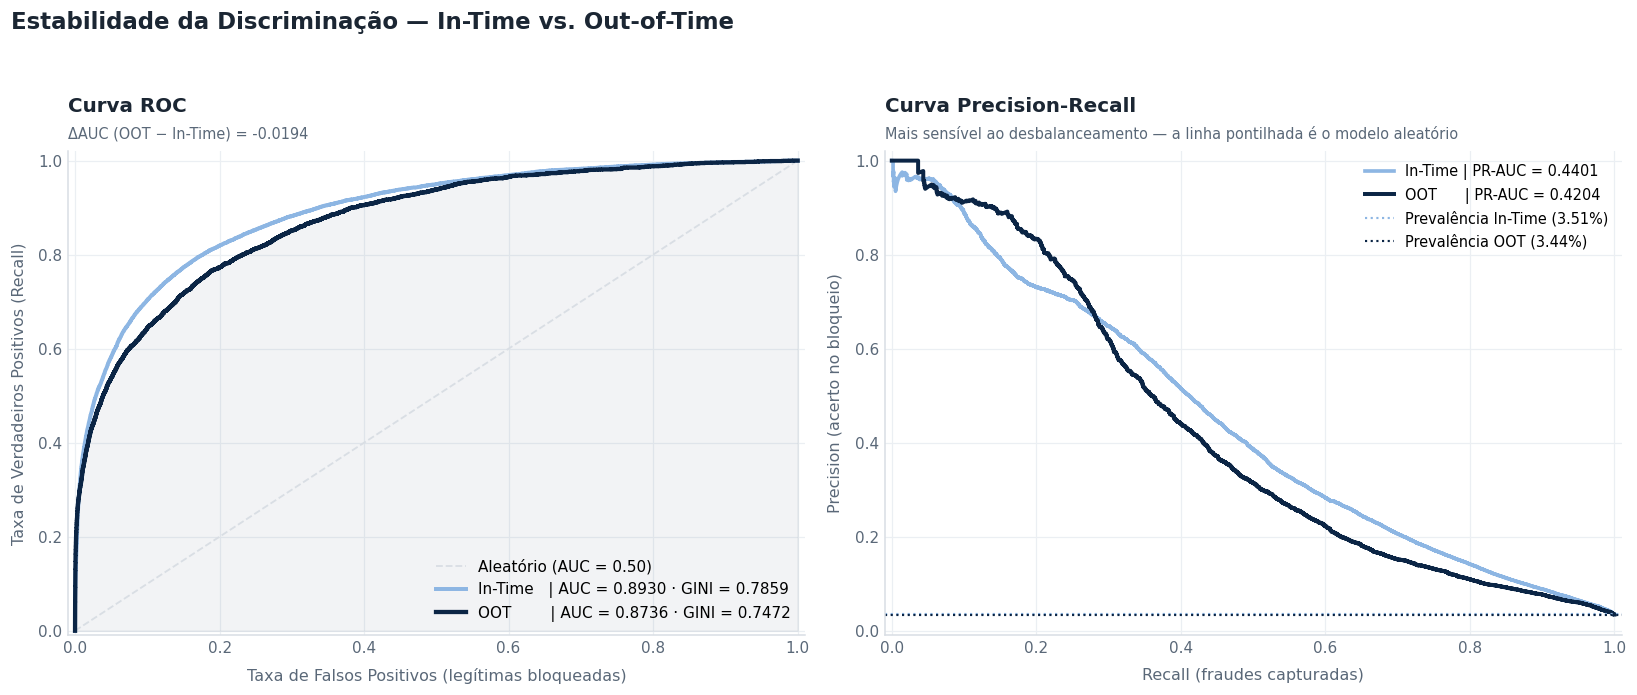

In [7]:
# ==============================================================================
# 3.0 CURVAS ROC E PR — IN-TIME x OOT
# ==============================================================================
aucs = plot_roc_pr_janelas(
    base_it['isFraud'], base_it['prob_raw'],
    base_oot['isFraud'], base_oot['prob_raw'],
    filepath=fig_path('04_02_roc_pr_in_time_vs_oot.png'),
)

> **Análise ROC-AUC e PR-AUC (In-Time vs. OOT)**
> 
> *   **Boa Estabilidade ROC-AUC:** A curva Out-of-Time (OOT) acompanha de perto a curva In-Time. A queda no AUC foi de **-0,0194** (de `0,8930` para `0,8736`).
> 
> *   **Sensibilidade ao Desbalanceamento (PR):** No gráfico da direita (PR), nota-se uma leve degradação na precisão em faixas de maior *Recall*. O PR-AUC caiu de **`0,4401`** para **`0,4204`**. Ainda assim, a curva OOT continua muito acima da linha pontilhada de prevalência (~3,44%), mostrando que o modelo ainda concentra acertos no topo da fila de risco.
> 
> *   **Conclusão:** `O modelo é estável na ordenação`, com perda moderada de discriminação fora do tempo.


___

## 4.0 Separação de Risco | KDE, KS e Escada de Decis

Avaliamos a estabilidade da separação de risco sob **três lentes complementares**, respondendo à mesma pergunta central: *as distribuições de score de fraudes e legítimas continuam nitidamente separadas?*

1. **KDE (Kernel Density Estimation):** Exibe a forma das distribuições por classe e a posição da **faixa do corte dinâmico**. Como o corte varia com o ticket, ele se desenha como uma faixa: a extremidade esquerda (corte menor e mais agressivo) aplica-se a transações de alto ticket, enquanto a extremidade direita (corte maior) aplica-se a micro-compras.

2. **KS (CDF):** Quantifica a distância máxima entre as distribuições acumuladas das classes, medindo o poder de discriminação global do modelo.

3. **Escada de Decis:** Avalia a monotonicidade da taxa de fraude e da captura acumulada (curva de ganho) ao longo dos decis de risco, provando que o score ordena corretamente a probabilidade de fraude.

---

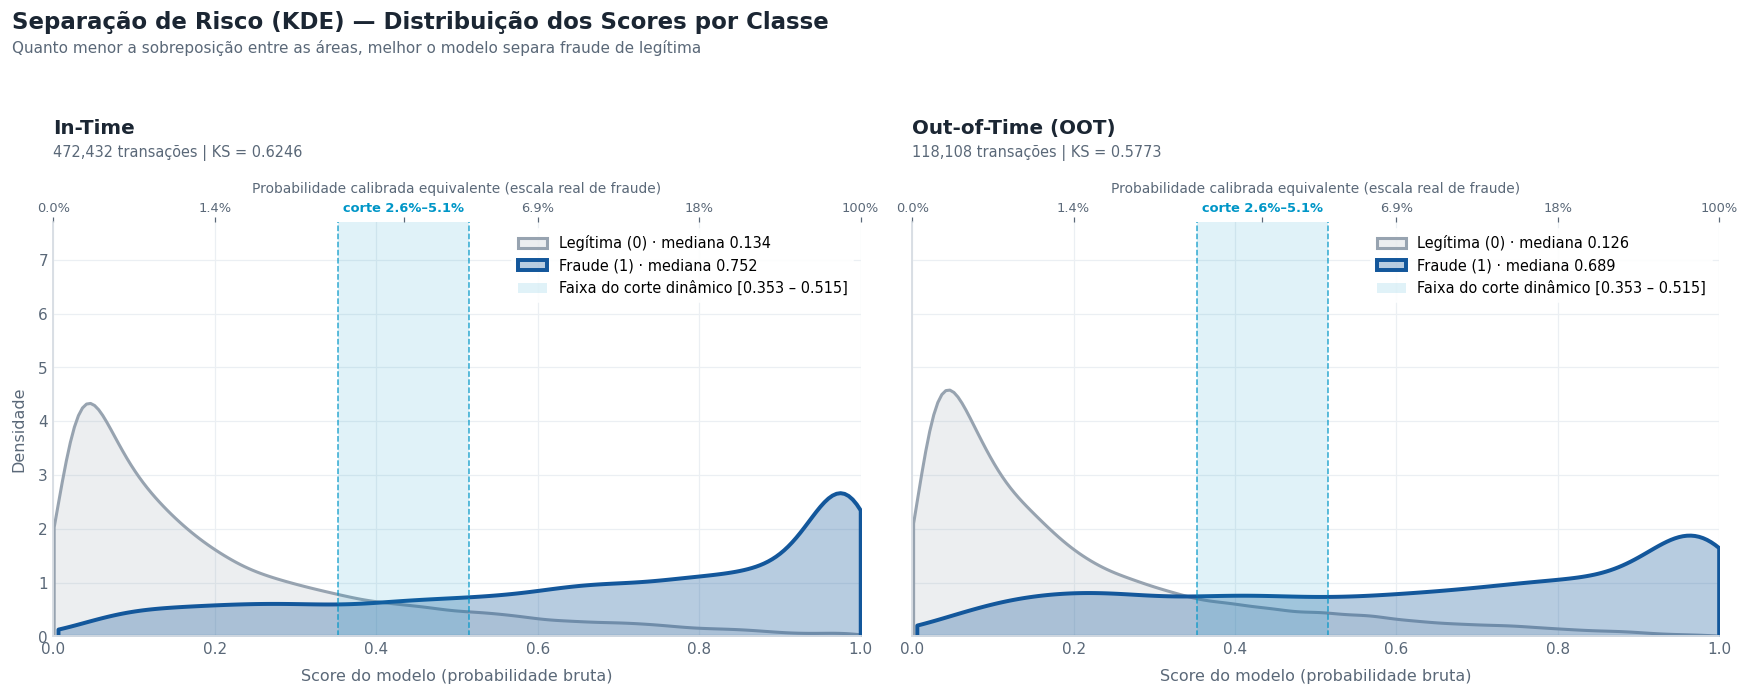

In [8]:
# ==============================================================================
# 4.1 SEPARAÇÃO DE RISCO (KDE) — IN-TIME x OOT
# ==============================================================================
plot_kde_scores_janelas(
    base_it['isFraud'], base_it['prob_raw'],
    base_oot['isFraud'], base_oot['prob_raw'],
    faixa_corte=FAIXA_CORTE_RAW,
    calibrador=artefato['calibrador'],   # eixo superior: probabilidade calibrada equivalente
    filepath=fig_path('04_03_kde_scores_in_time_vs_oot.png'),
)

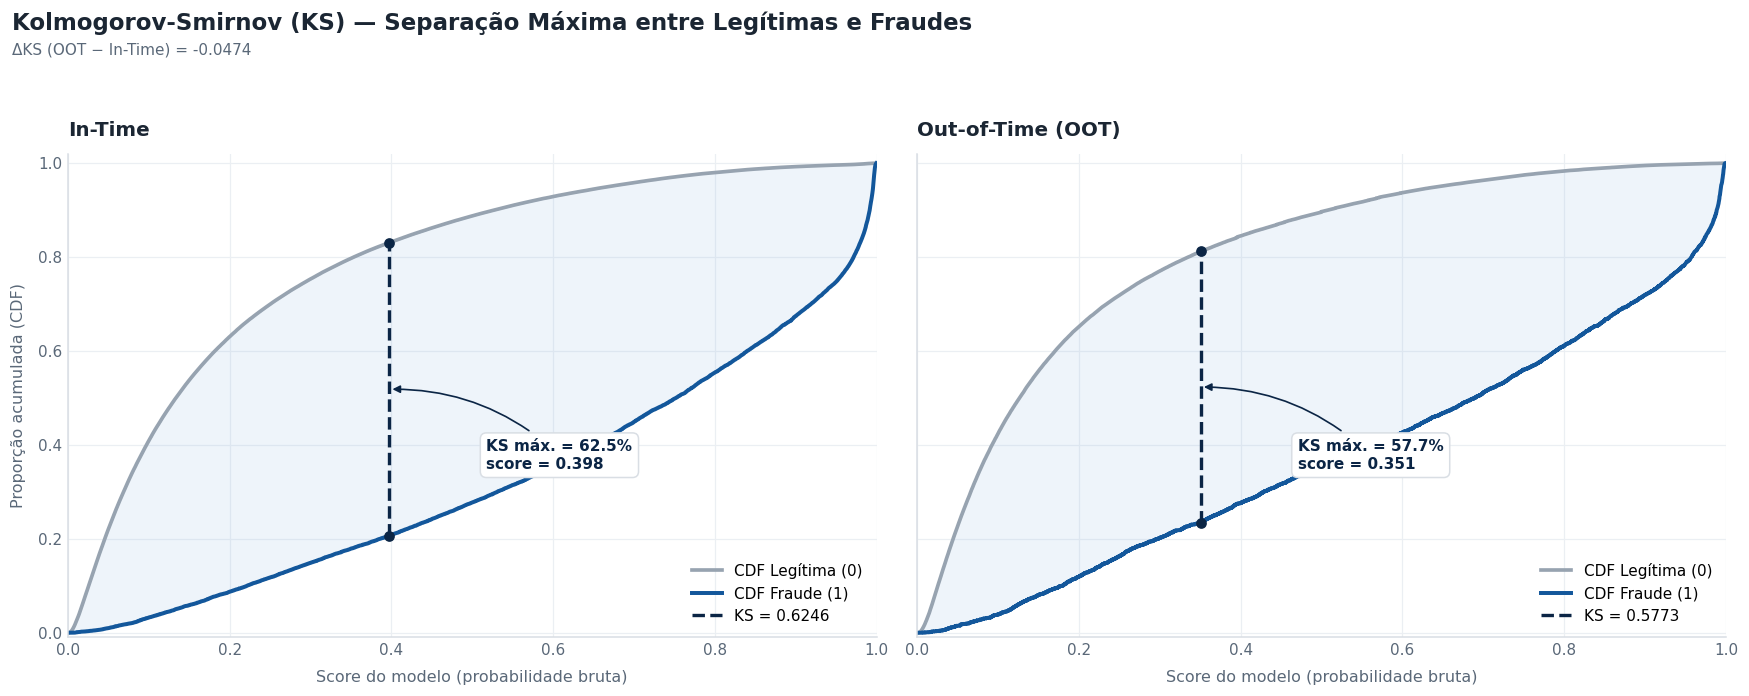

[KS] In-Time: 0.6246 | OOT: 0.5773 | Δ = -0.0474 (-7.6%)


In [9]:
# ==============================================================================
# 4.2 KOLMOGOROV-SMIRNOV (CDF) — IN-TIME x OOT
# ==============================================================================
ks_it, ks_oot = plot_cdf_ks_janelas(
    base_it['isFraud'], base_it['prob_raw'],
    base_oot['isFraud'], base_oot['prob_raw'],
    filepath=fig_path('04_04_cdf_ks_in_time_vs_oot.png'),
)
print(f"[KS] In-Time: {ks_it:.4f} | OOT: {ks_oot:.4f} | Δ = {ks_oot - ks_it:+.4f} ({(ks_oot / ks_it - 1) * 100:+.1f}%)")

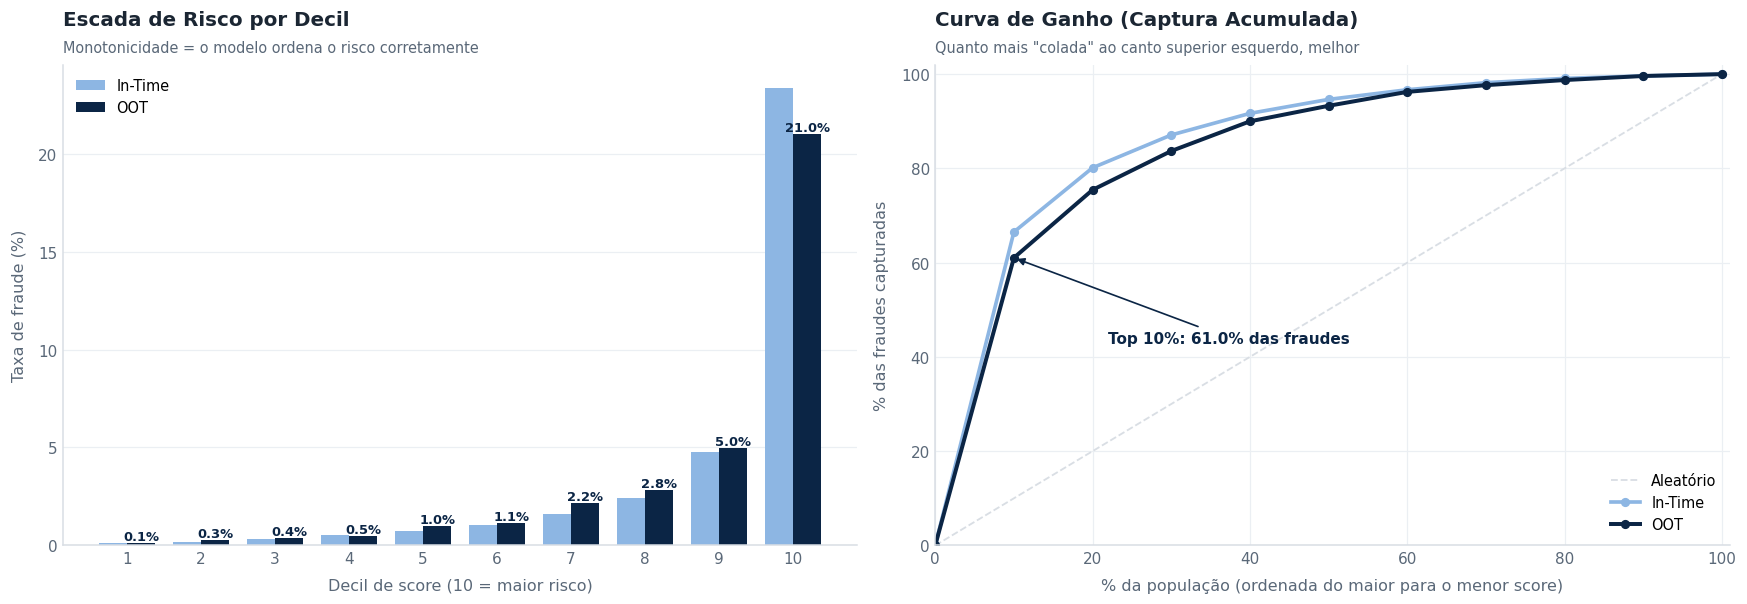

[OOT] Escada de risco monotônica: SIM | Decil 10: taxa de fraude 21.00% · lift 6.1x · captura 61.0% das fraudes


Decil,Transações,Fraudes,Taxa Fraude (%),Score Mín,Score Máx,Captura Acum. (%),KS Acum. (%),Lift
10,"11,811","2,480",21.00%,0.5514,0.9991,61.0%,52.8%,6.10x
9,"11,811",586,4.96%,0.3621,0.5514,75.4%,57.4%,1.44x
8,"11,811",335,2.84%,0.2503,0.3621,83.7%,55.6%,0.82x
7,"11,810",256,2.17%,0.1797,0.2503,90.0%,51.8%,0.63x
6,"11,811",134,1.13%,0.1325,0.1797,93.3%,44.8%,0.33x
5,"11,811",120,1.02%,0.0964,0.1325,96.2%,37.5%,0.30x
4,"11,810",58,0.49%,0.0685,0.0964,97.7%,28.6%,0.14x
3,"11,811",44,0.37%,0.0457,0.0685,98.7%,19.4%,0.11x
2,"11,811",35,0.30%,0.0261,0.0457,99.6%,9.9%,0.09x
1,"11,811",16,0.14%,0.0012,0.0261,100.0%,0.0%,0.04x


In [10]:
# ==============================================================================
# 4.3 ESCADA DE RISCO POR DECIL E CURVA DE GANHO — IN-TIME x OOT
# ==============================================================================
tab_decis_it = gerar_tabela_decis_ks(base_it['isFraud'], base_it['prob_raw'], n_decis=10)
tab_decis_oot = gerar_tabela_decis_ks(base_oot['isFraud'], base_oot['prob_raw'], n_decis=10)

plot_decis_janelas(tab_decis_it, tab_decis_oot, filepath=fig_path('04_05_decis_ganho_in_time_vs_oot.png'))

monotonico_oot = bool(np.all(np.diff(tab_decis_oot['taxa_fraude_pct']) >= 0))
top = tab_decis_oot.loc[tab_decis_oot['decil'] == 10].iloc[0]
print(f"[OOT] Escada de risco monotônica: {'SIM' if monotonico_oot else 'NÃO (há inversões)'} | "
      f"Decil 10: taxa de fraude {top['taxa_fraude_pct']:.2f}% · lift {top['lift']:.1f}x · "
      f"captura {top['captura_fraudes_acum_pct']:.1f}% das fraudes")

display(tab_decis_oot[['decil', 'transacoes', 'fraudes', 'taxa_fraude_pct', 'score_min', 'score_max',
                       'captura_fraudes_acum_pct', 'ks_pct', 'lift']]
        .sort_values('decil', ascending=False)
        .rename(columns={'decil': 'Decil', 'transacoes': 'Transações', 'fraudes': 'Fraudes',
                         'taxa_fraude_pct': 'Taxa Fraude (%)', 'score_min': 'Score Mín', 'score_max': 'Score Máx',
                         'captura_fraudes_acum_pct': 'Captura Acum. (%)', 'ks_pct': 'KS Acum. (%)', 'lift': 'Lift'})
        .style.format({'Transações': '{:,.0f}', 'Fraudes': '{:,.0f}', 'Taxa Fraude (%)': '{:.2f}%',
                       'Score Mín': '{:.4f}', 'Score Máx': '{:.4f}', 'Captura Acum. (%)': '{:.1f}%',
                       'KS Acum. (%)': '{:.1f}%', 'Lift': '{:.2f}x'})
        .bar(subset=['Taxa Fraude (%)'], color=PALETA_AZUL['claro'], vmin=0)
        .hide(axis='index'))

> **Análise Separação de Risco (KDE, KS e Decis)**
> 
> *   **Separação Robusta (KDE):** As `distribuições mantêm boa distinção`. A faixa do corte dinâmico na escala bruta (`0,3529 – 0,5149`) fica na região de transição entre as classes, onde a massa de legítimas já é baixa e a de fraudes começa a crescer.
>
> *   **Estabilidade de Discriminação (KS):** A distância máxima entre as curvas acumuladas (CDF) caiu de `0,6246` (In-Time) para `0,5773` (OOT). A queda de `-0,0474` (`-7,6%`) é moderada e o modelo preserva boa força de separação.
>
> *   **Monotonicidade e Lift (Decil):** O modelo ordena o risco sem inversões. A taxa de fraude salta de `0,14%` no 1º decil para **`21,00%` no 10º decil** (lift de `6,1x`), e os dois decis superiores capturam `75,4%` das fraudes.


___

## 5.0 Interpretabilidade — SHAP

Depois de medir **quanto** o modelo acerta, o SHAP revela **por que** ele decide. Ele calcula a contribuição de cada feature para a predição final, permitindo extrair três visões diretas:

1. **Importância Global (OOT):** Identifica as features que mais pesam na decisão do modelo no período futuro (com destaque para o Top 3).

2. **Direção do Impacto (Beeswarm):** Mostra para onde a feature empurra a predição. Valores altos (azul) aumentam ou diminuem a chance de ser fraude?

3. **Estabilidade (In-Time vs. OOT):** O ranking das features mais importantes continua o mesmo ao longo do tempo? Grandes mudanças indicam que o modelo passou a decidir com base em outros padrões.

[INFO] Calculando SHAP values (20,000 transações por janela)...


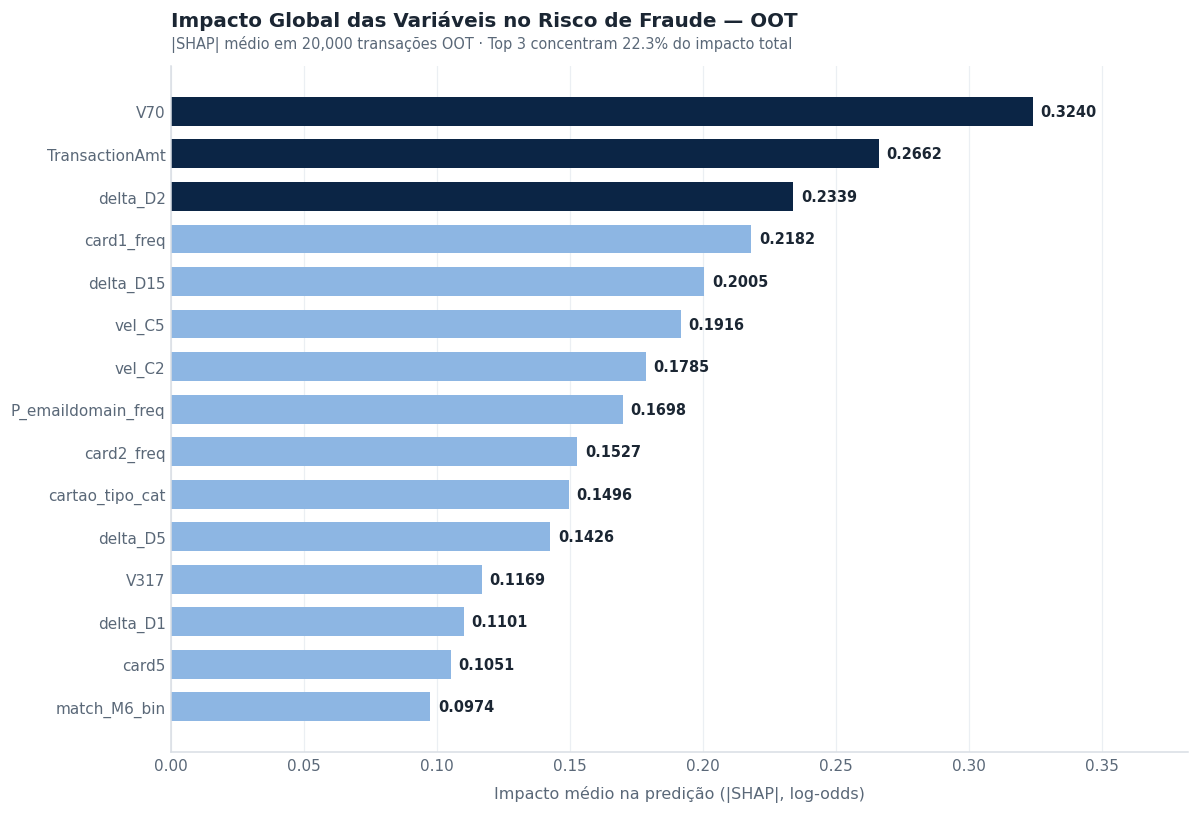

,Feature,SHAP_medio_abs,Rank,%_Impacto
0,V70,0.324032,1,8.787234
1,TransactionAmt,0.266184,2,7.218495
2,delta_D2,0.233940,3,6.344084
3,card1_freq,0.218213,4,5.917578
4,delta_D15,0.200482,5,5.436758
5,vel_C5,0.191635,6,5.196846
6,vel_C2,0.178473,7,4.839896
7,P_emaildomain_freq,0.169789,8,4.604413
8,card2_freq,0.152727,9,4.141701
9,cartao_tipo_cat,0.149621,10,4.057479


In [11]:
# ==============================================================================
# 5.1 SHAP VALUES (TREEEXPLAINER) — AMOSTRAS IN-TIME E OOT
# ==============================================================================
print(f"[INFO] Calculando SHAP values ({N_AMOSTRA_SHAP:,} transações por janela)...")
shap_oot, X_shap_oot = calcular_shap_lgbm(artefato['modelo'], X_oot_m, n_amostra=N_AMOSTRA_SHAP, random_state=RANDOM_STATE)
shap_it, X_shap_it = calcular_shap_lgbm(artefato['modelo'], X_in_time, n_amostra=N_AMOSTRA_SHAP, random_state=RANDOM_STATE)

rank_shap_oot = ranking_shap(shap_oot, FEATURES)
rank_shap_it = ranking_shap(shap_it, FEATURES)

plot_importancia_shap(
    rank_shap_oot, top_n=15, n_destaque=3,
    titulo='Impacto Global das Variáveis no Risco de Fraude — OOT',
    subtitulo=f"|SHAP| médio em {len(X_shap_oot):,} transações OOT · Top 3 concentram "
              f"{rank_shap_oot['%_Impacto'].head(3).sum():.1f}% do impacto total",
    filepath=fig_path('04_06_shap_importancia_oot.png'),
)

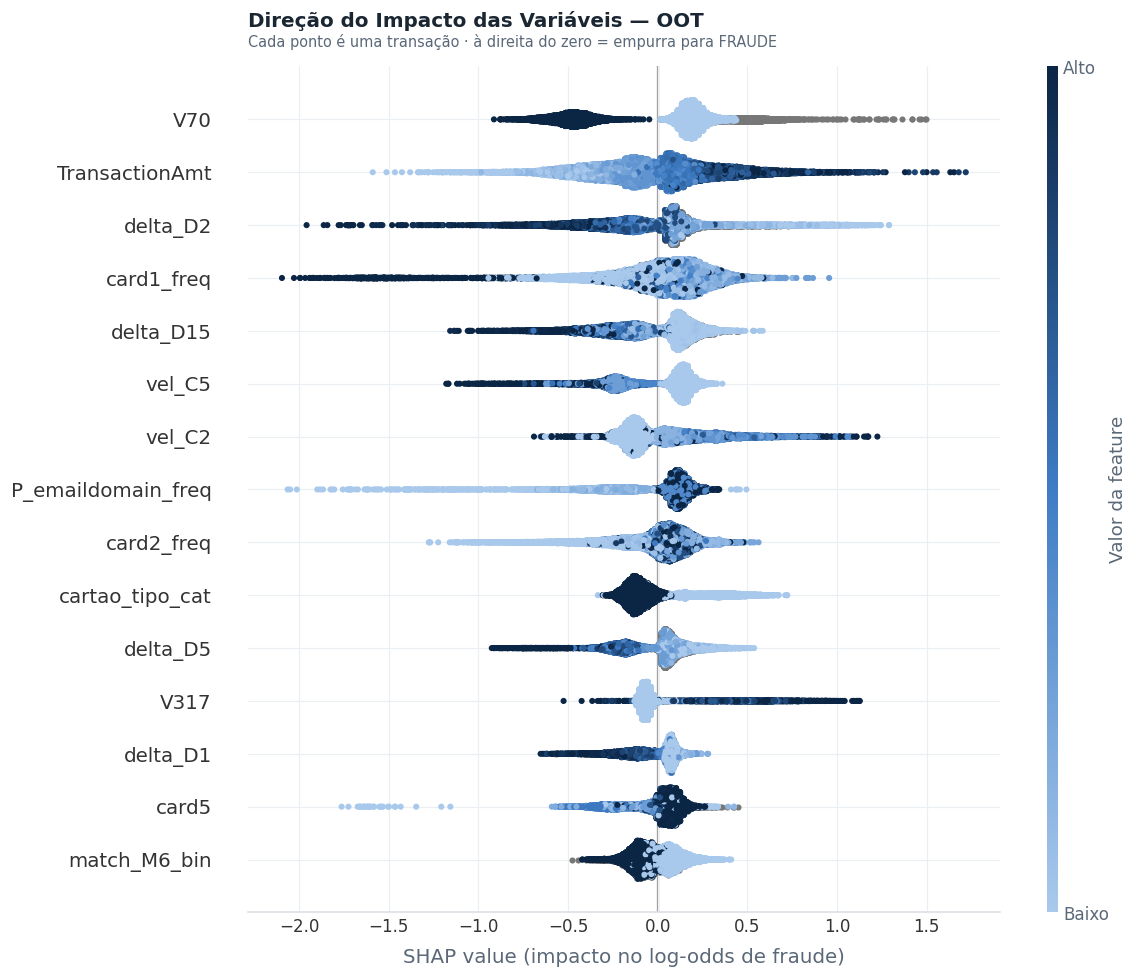

In [12]:
# ==============================================================================
# 5.2 DIREÇÃO DO IMPACTO (BEESWARM) — OOT
# ==============================================================================
plot_shap_beeswarm(shap_oot, X_shap_oot, top_n=15,
                   titulo='Direção do Impacto das Variáveis — OOT',
                   filepath=fig_path('04_07_shap_beeswarm_oot.png'))

> **Principais Insights SHAP (OOT)**
>
> *   **Os 3 Pilares:** `V70`, `TransactionAmt` e `delta_D2` são os maiores motores do modelo (Top 3 com `22,3%` do impacto), seguidos por `card1_freq`, `delta_D15`, `vel_C5` e `vel_C2`. O modelo combina um sinal anonimizado forte, o **valor** da compra, **features temporais**, a **raridade da faixa do cartão** e **velocidade**.
>
> *   **Lógica de Valor (`TransactionAmt`):** Quanto maior o valor da transação (pontos escuros), maior a propensão para fraude.
>
> *   **Lógica de Frequência (`card1_freq`):** Valores **altos** (faixas de cartão muito comuns) empurram **para legítima**; valores baixos empurram para fraude. Como `card1` identifica uma faixa/emissor do cartão (e não um cartão individual), o sinal é de **raridade**: faixas pouco vistas no Treino são mais arriscadas.
>
> *   **Lógica de Tempo (`delta_D2`, `delta_D15`):** Valores baixos (pontos claros) empurram para a fraude. Contas muito "novas" ou com ações muito recentes têm alto risco de ataque.
>
> *   **Lógica de Velocidade (`vel_C2`):** Valores altos (pontos escuros) **empurram para a fraude**, caracterizando o comportamento de bots/card testing. Já em `vel_C5` o efeito é o oposto (valores altos reduzem o risco).
>
> *   **Sinais Anonimizados e Cadastrais:** `V70` baixo aumenta o risco e `V70` alto reduz; `match_M6_bin = 1` (validação aprovada) reduz o risco, `V317` alto aumenta, e `cartao_tipo_cat` aponta maior risco para cartões de crédito.
>
> *   **Estabilidade dos Motores:** a correlação de Spearman entre os rankings de |SHAP| In-Time e OOT é de **`0,934`** (Seção 9.0): o modelo decide pelos mesmos motivos nas duas janelas.

___
## 6.0 Análise de Drift

Um modelo pode perder performance por três caminhos: 

- (i) a Taxa do evento muda (*target drift*),

- **(ii)** a população de entrada muda (*data drift*, medido pelo **PSI**) ou 

- **(iii)** a relação entre features e fraude muda (*concept drift*, percebido pela queda do GINI na Seção 7.0).

| Faixa de PSI | Diagnóstico | Ação recomendada |
|:---:|:---:|---|
| PSI < 0,10 | Estável | Nenhuma intervenção |
| 0,10 ≤ PSI < 0,25 | Alerta (drift moderado) | Monitoramento intensificado |
| PSI ≥ 0,25 | Crítico (drift severo) | Investigar causa; avaliar re-treino/recalibração |

_________

### 6.1 Target Drift 

- Taxa de fraude por **semana** em todo o horizonte (Treino → Validação → OOT), com as médias de cada janela.

- O teste **Qui-Quadrado** verifica se a taxa varia significativamente entre semanas e o **V de Cramér** mede se essa variação é relevante na prática

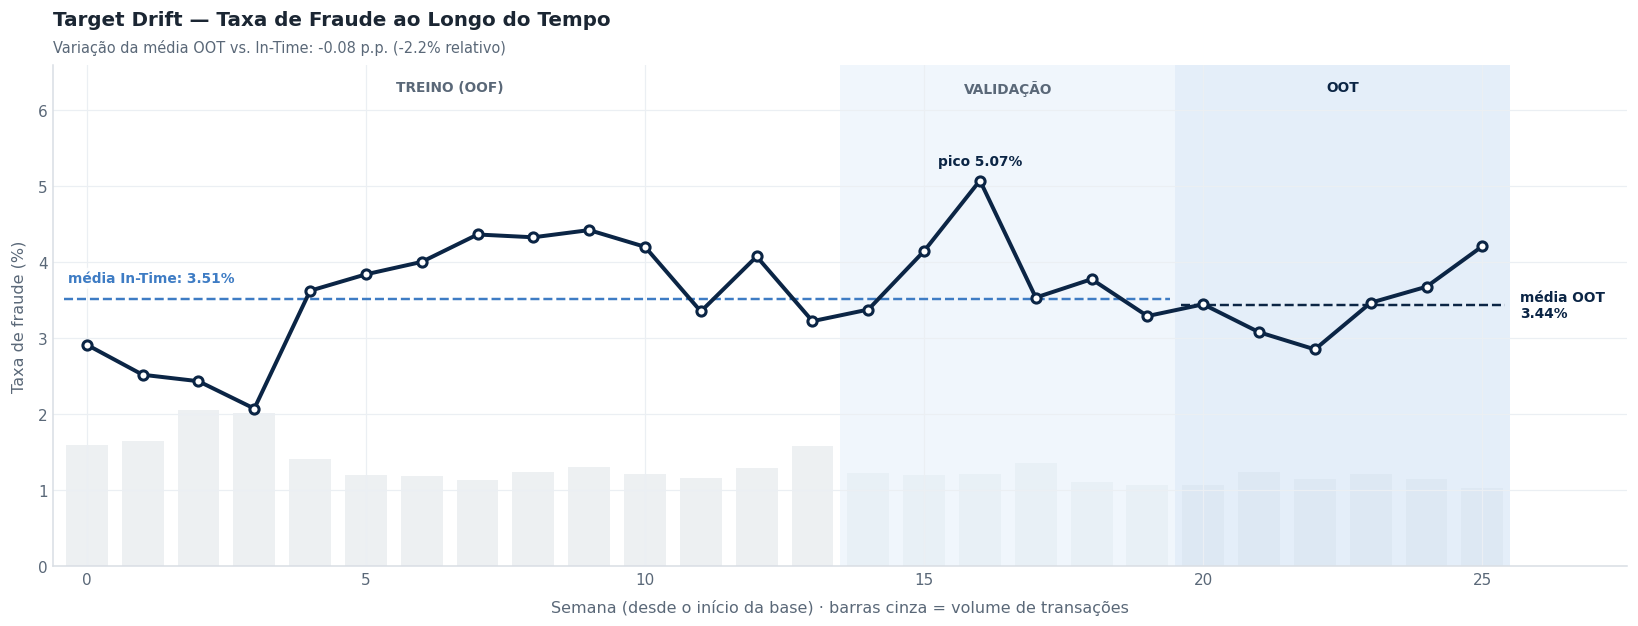

[Qui² — semanas (heterogeneidade temporal)] χ² = 918.16 | gl = 25 | p-valor = 1.29e-177 | V de Cramér = 0.0394 (efeito desprezível)
[Qui² — In-Time x OOT] χ² = 1.45 | gl = 1 | p-valor = 2.28e-01 | V de Cramér = 0.0016 (efeito desprezível)


In [13]:
# ==============================================================================
# 6.1 TARGET DRIFT SEMANAL + TESTE QUI-QUADRADO
# ==============================================================================
df_temporal = tabela_temporal(df_scores, col_bloco='semana', min_fraudes=30, min_transacoes=1000)
medias_taxa = plot_target_drift_temporal(df_temporal, col_bloco='semana', rotulo_bloco='Semana',
                                         filepath=fig_path('04_08_target_drift_semanal.png'))

# (a) A taxa de fraude varia entre as semanas?
chi2_semanas = teste_qui_quadrado_temporal(df_temporal, rotulo='semanas (heterogeneidade temporal)')
# (b) A taxa de fraude do OOT difere da In-Time?
tab_janelas = df_scores.groupby('Janela').agg(Fraudes=('isFraud', 'sum'), Transacoes=('isFraud', 'size'))
chi2_janelas = teste_qui_quadrado_temporal(tab_janelas, rotulo='In-Time x OOT')

df_temporal.to_csv(DIR_METRICAS / 'avaliacao_metricas_semanais.csv', index=False)

> **Análise de Target Drift**
> 
> *   **Estabilidade Estrutural:** A taxa de fraude média entre In-Time (3,51%) e OOT (3,44%) teve uma variação ínfima de **-0,07 p.p.** (-2,0% relativo). A prevalência da fraude no futuro é praticamente idêntica à do treinamento.
>
> *   **Significância Estatística vs. Prática:** O teste Qui-quadrado semanal detecta variação (p < 0,05), mas o **V de Cramér (0,0394)** confirma que o efeito é **praticamente desprezível**. Além disso, a comparação direta In-Time x OOT não apresenta diferença estatística significativa (p = 0,228).
>


### 6.2 PSI do Score (Estabilidade Populacional Global)

- O PSI do **score** é o indicador-síntese de estabilidade

- Mesmo que features isoladas sofram drift, o que importa para a decisão é se a **distribuição final de risco** mudou. 

- As faixas são os decis do score In-Time (cada uma com 10% da população por construção).

[PSI do Score] PSI = 0.0028 → Estável
[KS shift do score] estatística = 0.0231 (p-valor = 2.76e-44)


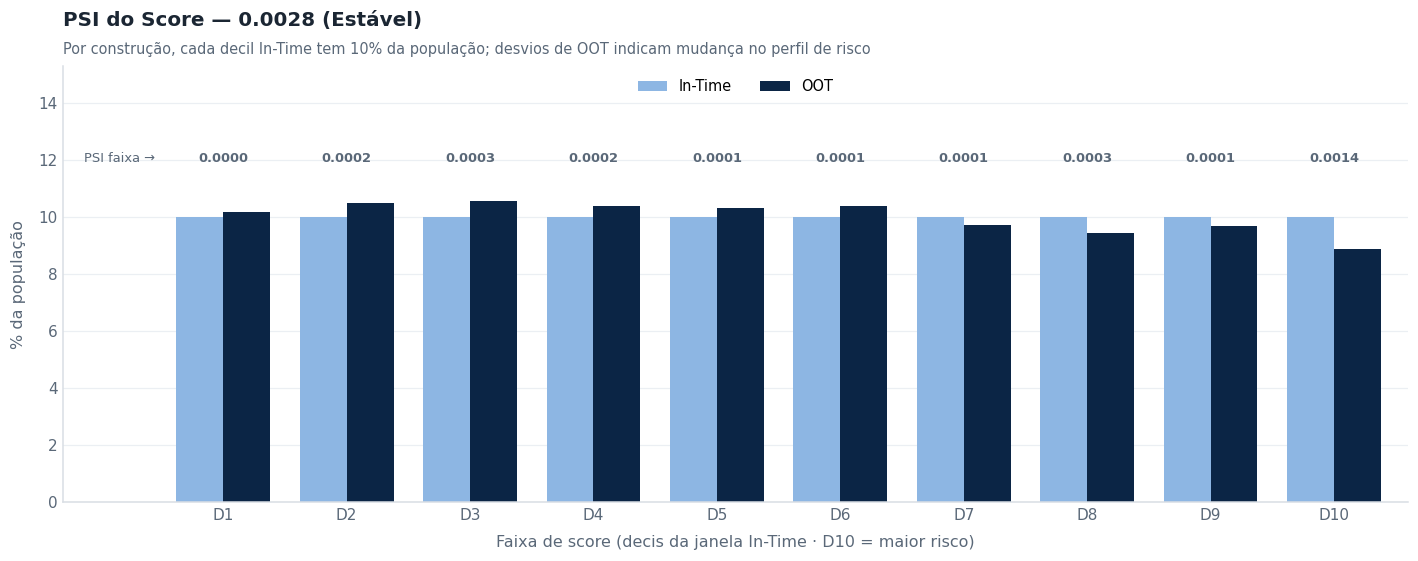

In [14]:
# ==============================================================================
# 6.2 PSI GLOBAL DO SCORE + KS DE DESLOCAMENTO
# ==============================================================================
df_psi_score, psi_score = calcular_psi_scores(base_it['prob_raw'], base_oot['prob_raw'], bins=10)
ks_shift = ks_2samp(base_it['prob_raw'], base_oot['prob_raw'])
print(f"[KS shift do score] estatística = {ks_shift.statistic:.4f} (p-valor = {ks_shift.pvalue:.2e})")

plot_psi_score_faixas(df_psi_score, psi_score, filepath=fig_path('04_09_psi_score_faixas.png'))

>
> **Veja que as faixas são bem estáveis (PSI do score = `0,0028`), sem mudança significativa na população**
>
> **Mas, será que existem features isoladas que mudam gravemente?**


### 6.3 PSI das Features × Importância (SHAP)

Drift só é um problema quando atinge variáveis que **o modelo usa**. Por isso cruzamos o PSI de cada uma das features do modelo com o seu |SHAP| médio (Seção 5.0): o **Risco de Drift** = PSI × % de impacto SHAP prioriza o que monitorar.

In [15]:
# ==============================================================================
# 6.3a PSI DE TODAS AS FEATURES DO MODELO (IN-TIME → OOT)
# ==============================================================================
df_psi_features = relatorio_psi_features(X_in_time, X_oot_m, features=FEATURES, bins=10)
contagem_status = df_psi_features['Status'].value_counts().reindex(['Estável', 'Alerta', 'Crítico'], fill_value=0)
print(f"[PSI features] Estável: {contagem_status['Estável']} | Alerta: {contagem_status['Alerta']} | "
      f"Crítico: {contagem_status['Crítico']} (de {len(df_psi_features)} features do modelo)")

display(df_psi_features.head(15).style.format({
    'PSI': '{:.4f}', 'KS_shift': '{:.4f}', '%_Nulos_InTime': '{:.1f}%', '%_Nulos_OOT': '{:.1f}%',
}).bar(subset=['PSI'], color=PALETA_AZUL['claro'], vmin=0).hide(axis='index'))
df_psi_features.to_csv(DIR_METRICAS / 'avaliacao_psi_features.csv', index=False)

[PSI features] Estável: 29 | Alerta: 1 | Crítico: 0 (de 30 features do modelo)


Feature,PSI,KS_shift,Status,%_Nulos_InTime,%_Nulos_OOT
match_cont_F,0.1272,0.1680,Alerta,0.0%,0.0%
delta_D8,0.0625,0.0638,Estável,87.0%,88.7%
delta_D15,0.0477,0.0901,Estável,16.5%,9.6%
delta_D10,0.0254,0.0619,Estável,14.1%,8.2%
delta_D1,0.0240,0.0757,Estável,0.2%,0.3%
ProductCD,0.0203,0.0731,Estável,0.0%,0.0%
V156,0.0172,0.0593,Estável,85.2%,89.6%
vel_C8,0.0166,0.0537,Estável,0.0%,0.0%
delta_D2,0.0156,0.0540,Estável,49.0%,41.9%
tempo_hora,0.0145,0.0400,Estável,0.0%,0.0%


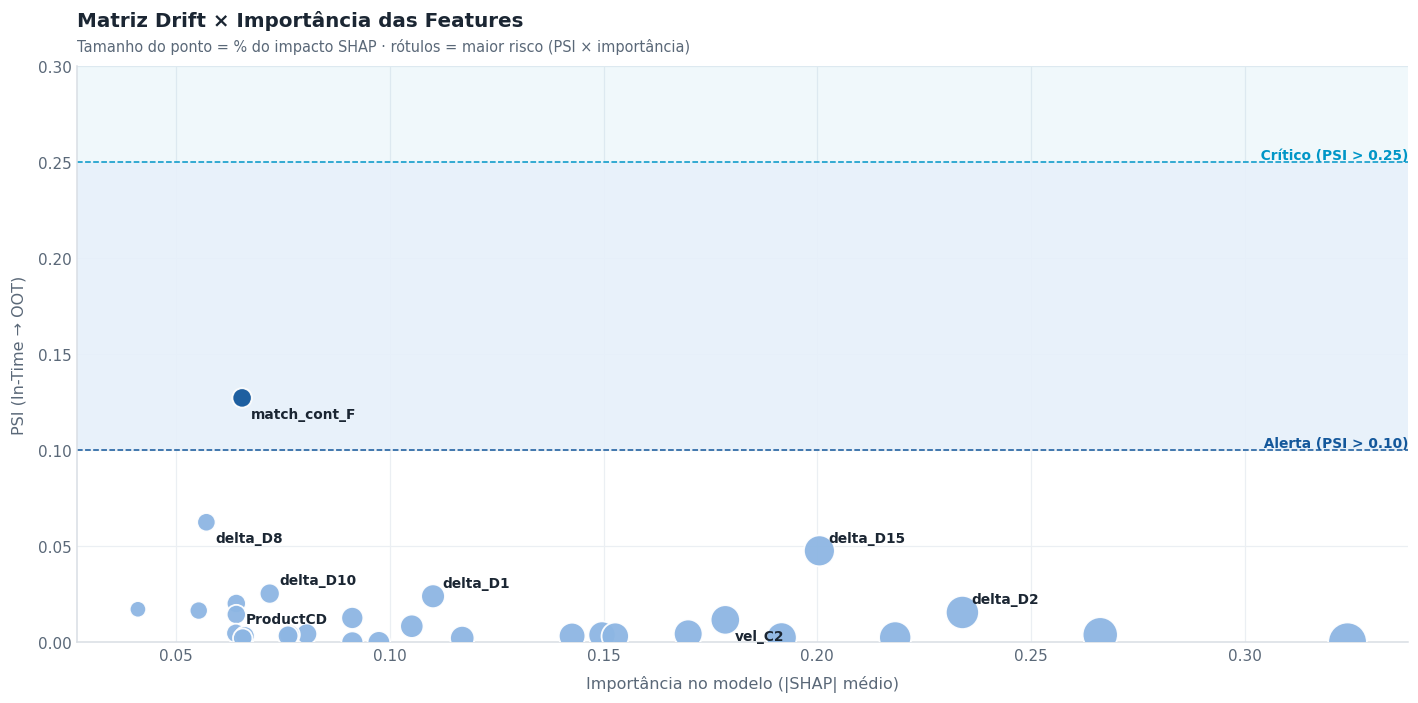

Feature,PSI,Status,Rank SHAP,% Impacto SHAP,Risco_Drift
delta_D15,0.0477,Estável,5,5.44%,0.259
match_cont_F,0.1272,Alerta,24,1.77%,0.226
delta_D2,0.0156,Estável,3,6.34%,0.099
delta_D8,0.0625,Estável,28,1.55%,0.097
delta_D1,0.0240,Estável,13,2.99%,0.072
vel_C2,0.0117,Estável,7,4.84%,0.057
delta_D10,0.0254,Estável,21,1.95%,0.050
ProductCD,0.0203,Estável,26,1.74%,0.035
V258,0.0127,Estável,17,2.47%,0.031
TransactionAmt,0.0040,Estável,2,7.22%,0.029


In [16]:
# ==============================================================================
# 6.3b MATRIZ DRIFT x IMPORTÂNCIA (PSI x |SHAP|)
# ==============================================================================
df_drift_risco = plot_psi_vs_shap(df_psi_features, rank_shap_oot, n_rotulos=8,
                                  filepath=fig_path('04_10_matriz_psi_vs_shap.png'))
display(df_drift_risco.head(10)[['Feature', 'PSI', 'Status', 'Rank', '%_Impacto', 'Risco_Drift']]
        .rename(columns={'Rank': 'Rank SHAP', '%_Impacto': '% Impacto SHAP'})
        .style.format({'PSI': '{:.4f}', '% Impacto SHAP': '{:.2f}%', 'Risco_Drift': '{:.3f}'})
        .hide(axis='index'))

[INFO] Features com maior risco de drift (PSI x importância): delta_D15, match_cont_F, delta_D2


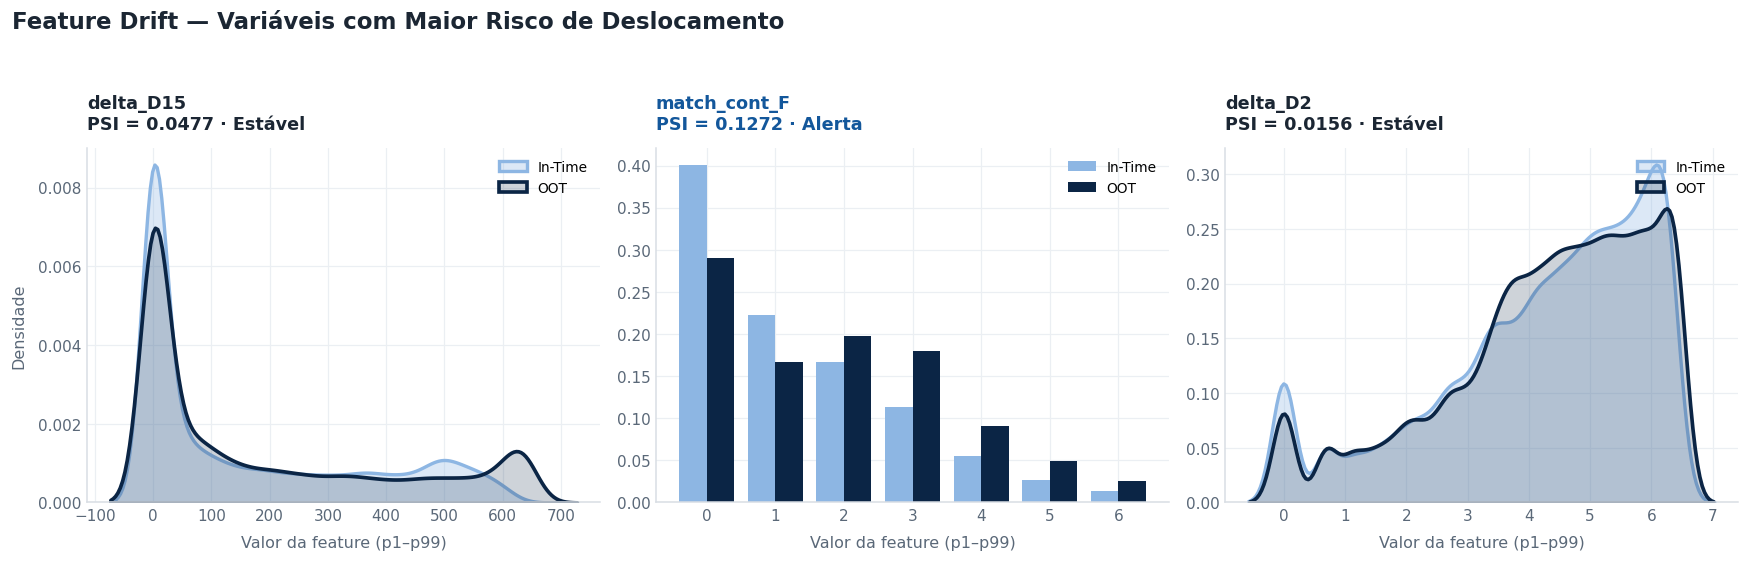

In [17]:
# ==============================================================================
# 6.3c DISTRIBUIÇÕES IN-TIME x OOT DAS 3 FEATURES DE MAIOR RISCO DE DRIFT
# ==============================================================================
top3_drift = df_drift_risco['Feature'].head(3).tolist()
print(f"[INFO] Features com maior risco de drift (PSI x importância): {', '.join(top3_drift)}")
plot_comparativo_psi_features(X_in_time, X_oot_m, top3_drift, bins=10,
                              filepath=fig_path('04_11_feature_drift_top3.png'))

> **Análise de Feature Drift (Explicação e Consistência)**
>
> Das `30` features do modelo, `29` estão estáveis, `1` em Alerta (`match_cont_F`) e nenhuma em nível Crítico. Ponderando pela importância, as 3 de maior risco são:
>
> *   **`delta_D15` (PSI 0,048 | Estável | rank SHAP 5):**
>     *   **O que mudou:** Queda na taxa de nulos (de 16,5% para 9,6%) e surgimento de cauda longa.
>     *   **É consistente?** Sim. É o efeito natural do tempo sobre deltas sem ancoragem: contas mais antigas acumulam dias desde o último evento, e o sistema pode ter melhorado a captura desses dados no período recente. Como é a 5ª variável mais importante, lidera o risco de drift mesmo estando estável.
>
> *   **`match_cont_F` (PSI 0,127 | Alerta | rank SHAP 24):**
>     *   **O que mudou:** A distribuição de reprovações cadastrais (bloco M) se deslocou, com mais transações com falhas no OOT.
>     *   **É consistente?** Possivelmente. Pode refletir validações chegando mais "sujas" no futuro (dados sintéticos ou desatualizados), mas também mudança no mix de produtos que passam pelo bloco M.
>
> *   **`delta_D2` (PSI 0,016 | Estável | rank SHAP 3):**
>     *   **O que mudou:** Pouco: a taxa de nulos cai de 49,0% para 41,9%. Entra no top 3 apenas pelo peso no modelo.
>
> *   **Cobertura dos blocos D e M:** os nulos de `delta_D10`, `delta_D15`, `V70`, `match_M3_bin` e `match_M6_bin` **caem** no OOT (ex.: `match_M3_bin` de 50,4% para 27,8%), enquanto `V156`, `V164` e `V258` ficam mais vazias (~85% → ~90%). É uma mudança de **cobertura de dados**, não de comportamento.
>
> **Diagnóstico Final:** As variações são **comportamentais, temporais ou de cobertura de dados**, não anomalias estruturais. Os motores principais do modelo (`V70`, `TransactionAmt`, `delta_D2`, `card1_freq`) permanecem estáveis no OOT (PSI < 0,02).

---
## 7.0 Estabilidade Temporal do GINI


- Determinando se métricas como GINI são estáveis durante o tempo, semana a semana, a performance pode se tornar degradada por causa desse drift de métricas

- O piso de aceitação é definido como **90% do GINI médio In-Time** (tolerância de queda relativa de 10%).

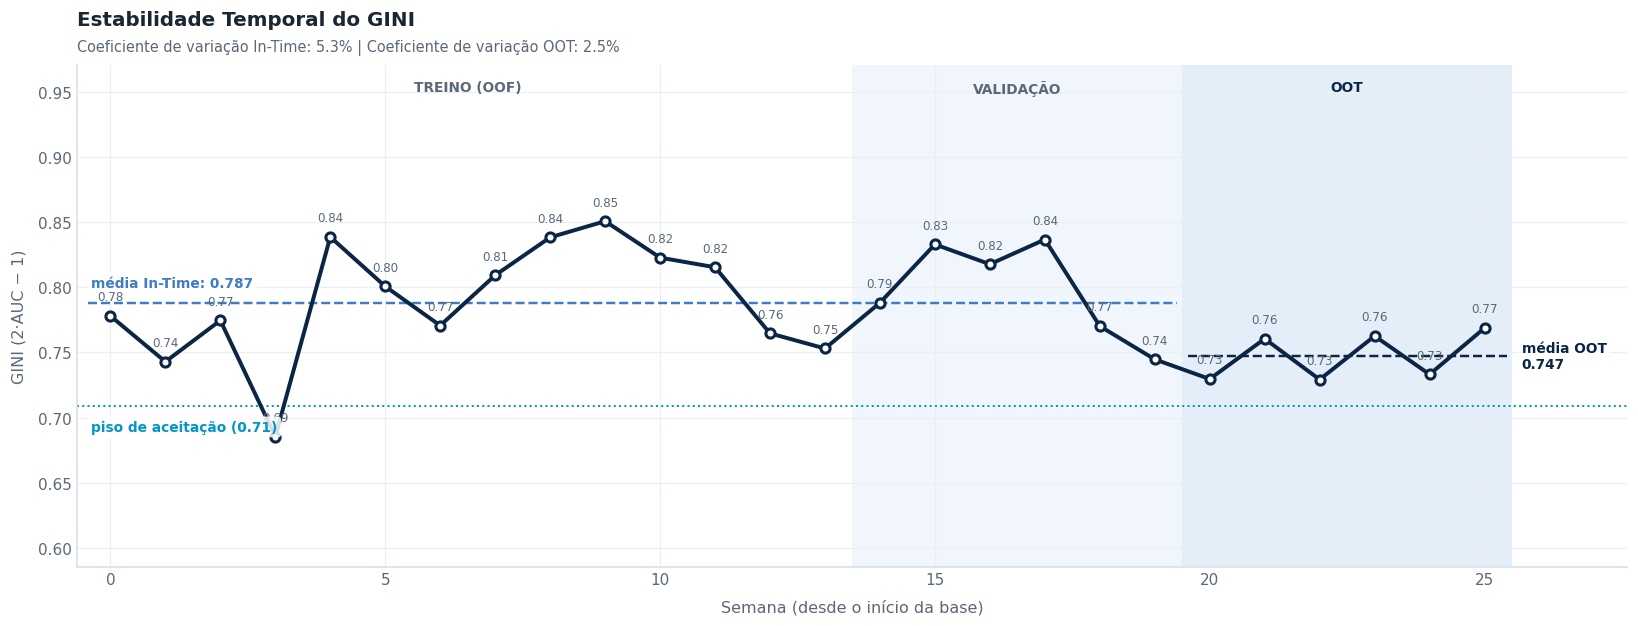

[GINI] Médio In-Time: 0.7875 | Médio OOT: 0.7474 | Piso: 0.7087
[GINI] Semanas OOT abaixo do piso: nenhuma
[GINI] Tendência no OOT: +0.0042 por semana | Correlação taxa de fraude x GINI: +0.65


semana,Particao,Transacoes,Fraudes,Taxa_Fraude_%,GINI,KS,Recall_%,Precision_%,Lucro_USD
0,Treino (OOF),"27,596",804,2.91%,0.7779,0.6260,73.9%,14.9%,"$ 12,574"
1,Treino (OOF),"28,463",717,2.52%,0.7428,0.6040,76.3%,10.3%,"$ 23,174"
2,Treino (OOF),"35,701",869,2.43%,0.7745,0.6129,78.7%,9.5%,"$ 27,301"
3,Treino (OOF),"34,906",724,2.07%,0.6854,0.5314,77.3%,6.5%,"$ 20,123"
4,Treino (OOF),"24,539",889,3.62%,0.8385,0.6791,79.0%,20.3%,"$ 21,850"
5,Treino (OOF),"20,919",803,3.84%,0.8006,0.6424,73.2%,20.9%,"$ 9,564"
6,Treino (OOF),"20,564",823,4.00%,0.7705,0.5898,69.0%,20.4%,"$ 9,871"
7,Treino (OOF),"19,761",862,4.36%,0.8091,0.6519,75.1%,22.9%,"$ 13,558"
8,Treino (OOF),"21,432",927,4.33%,0.8382,0.6878,78.9%,25.6%,"$ 15,237"
9,Treino (OOF),"22,534",996,4.42%,0.8506,0.7127,79.8%,27.3%,"$ 21,149"


In [18]:
# ==============================================================================
# 7.0 GINI SEMANA A SEMANA (TREINO OOF → VALIDAÇÃO → OOT)
# ==============================================================================
TOLERANCIA_QUEDA_GINI = 0.10
d_it = df_temporal[df_temporal['Janela'] == 'In-Time'].dropna(subset=['GINI'])
gini_medio_it = float(np.average(d_it['GINI'], weights=d_it['Transacoes']))
PISO_GINI = gini_medio_it * (1 - TOLERANCIA_QUEDA_GINI)

medias_gini = plot_gini_temporal(df_temporal, col_bloco='semana', rotulo_bloco='Semana', piso_gini=PISO_GINI,
                                 filepath=fig_path('04_12_gini_temporal_semanal.png'))

d_oot = df_temporal[df_temporal['Janela'] == 'OOT'].dropna(subset=['GINI'])
semanas_abaixo = d_oot.loc[d_oot['GINI'] < PISO_GINI, 'semana'].tolist()
tendencia_oot = np.polyfit(d_oot['semana'], d_oot['GINI'], 1)[0] if len(d_oot) >= 3 else np.nan
corr_taxa_gini = df_temporal[['Taxa_Fraude_%', 'GINI']].corr().iloc[0, 1]

print(f"[GINI] Médio In-Time: {gini_medio_it:.4f} | Médio OOT: {medias_gini.get('OOT', np.nan):.4f} | Piso: {PISO_GINI:.4f}")
print(f"[GINI] Semanas OOT abaixo do piso: {semanas_abaixo if semanas_abaixo else 'nenhuma'}")
print(f"[GINI] Tendência no OOT: {tendencia_oot:+.4f} por semana | Correlação taxa de fraude x GINI: {corr_taxa_gini:+.2f}")

display(df_temporal[['semana', 'Particao', 'Transacoes', 'Fraudes', 'Taxa_Fraude_%', 'GINI', 'KS', 'Recall_%',
                     'Precision_%', 'Lucro_USD']]
        .style.format({'Transacoes': '{:,.0f}', 'Fraudes': '{:,.0f}', 'Taxa_Fraude_%': '{:.2f}%', 'GINI': '{:.4f}',
                       'KS': '{:.4f}', 'Recall_%': '{:.1f}%', 'Precision_%': '{:.1f}%', 'Lucro_USD': '$ {:,.0f}'}, na_rep='—')
        .background_gradient(subset=['GINI'], cmap=CMAP_AZUL)
        .hide(axis='index'))

> **Análise de Drift do GINI (Estabilidade Temporal)**
>
> *   **Estável no OOT:** O coeficiente de variação do GINI semanal no OOT é de **`2,5%`** (contra `5,3%` no In-Time), e a tendência é levemente positiva (`+0,0042` por semana).
>
> *   **Queda Moderada:** A média semanal caiu de `0,7875` (In-Time) para `0,7474` (OOT). O `GINI nunca cruza o piso de aceitação (0,7087)`, com a pior semana do OOT em `0,7291`.
>
> *   **Impacto Operacional:** O Recall semanal no OOT ficou entre `61,5%` e `71,7%` (abaixo do In-Time, que oscila entre `65%` e `80%`), com Precision entre `14,1%` e `20,2%`.
>
> *   **Resultado Financeiro:** As seis semanas do OOT geraram lucro (de `US$ 1,3 mil` a `US$ 11,6 mil`), mas com forte oscilação: as semanas 24 e 25 caem para `US$ 1,3 mil` e `US$ 2,9 mil` (a menor semana da Validação foi a 14, com `US$ 1,3 mil`). O lucro semanal é sensível a semanas com mais fraude de alto valor.

---
## 8.0 Modelo × Clusters de Fraude | Onde o Modelo Falha?

- O `03_Segmentacao` agrupou as fraudes do **Treino** em **12 clusters (K-Means no UMAP 10D)**, consolidados em **4 grupos de ataque**. Aqui os mesmos clusters são reajustados no Treino (com checagem de que os IDs são idênticos ao `03`) e as fraudes de **Validação e OOT são apenas projetadas** neles, sem participar do ajuste. Como os clusters existem apenas para fraudes, a pergunta natural é: 

- **Qual fração de cada tipo de ataque o modelo barra (Recall) e quanto dinheiro escapa (FN em US$)?**

### 8.1 Rótulos de Cluster e Grupo

In [19]:
# ==============================================================================
# 8.1 RÓTULOS DE CLUSTER (K=12) E GRUPOS — MESMO MAPEAMENTO DO 03_SEGMENTACAO
# ==============================================================================
K_CLUSTERS = 12  # mesmo K_ESCOLHIDO do 03_Segmentacao

# Copiado de MAPA_CLUSTER_ARQUETIPO (03_Segmentacao, Seção 6.0)
MAPA_CLUSTER_GRUPO = {
    1: '1. Cartão Clonado', 5: '1. Cartão Clonado',
    0: '2. Botnet', 2: '2. Botnet', 6: '2. Botnet', 7: '2. Botnet', 9: '2. Botnet', 10: '2. Botnet',
    3: '3. Roubo de Contas (ATO)', 8: '3. Roubo de Contas (ATO)', 11: '3. Roubo de Contas (ATO)',
    4: '4. Ataque Inteligente',
}

# Tamanho de cada cluster nas fraudes do Treino, segundo a tabela 5.1 do 03_Segmentacao
# (usado para confirmar que o 04 reproduziu exatamente os mesmos IDs de cluster)
TAMANHOS_CLUSTER_03 = {
    1: 3710, 5: 1655, 2: 1408, 7: 816, 3: 798, 6: 747,
    0: 685, 10: 550, 4: 547, 11: 523, 8: 291, 9: 258,
}
ORDEM_GRUPOS = [
    '1. Cartão Clonado',
    '2. Botnet',
    '3. Roubo de Contas (ATO)',
    '4. Ataque Inteligente',
]
PALETA_GRUPOS = dict(zip(ORDEM_GRUPOS, [PALETA_AZUL['marinho'], PALETA_AZUL['principal'],
                                        PALETA_AZUL['ciano'], PALETA_AZUL['claro']]))

# O cache leva o K no nome (exportado pelo 03_Segmentacao). Use True se o df_master ou o 03 mudarem.
FORCAR_RECALCULO_CLUSTERS = False

df_clusters = obter_rotulos_clusters_fraude(
    df_master, meta, MAPA_CLUSTER_GRUPO,
    caminho_cache=dir_dados / f'fraude_clusters_treino_k{K_CLUSTERS}.parquet',
    k=K_CLUSTERS, random_state=RANDOM_STATE,
    forcar_recalculo=FORCAR_RECALCULO_CLUSTERS,
)
mapa_id_cluster = df_clusters.set_index('TransactionID')['cluster']

# Sanidade: os clusters ajustados aqui precisam ser os mesmos do 03 (mesmo ID -> mesmo tamanho no Treino)
tamanhos_04 = df_clusters.loc[df_clusters['base_cluster'] == 'Treino (ajuste)', 'cluster'].value_counts().to_dict()
difs_tamanho = {c: (n, tamanhos_04.get(c, 0)) for c, n in TAMANHOS_CLUSTER_03.items() if tamanhos_04.get(c, 0) != n}
assert not difs_tamanho, f'Clusters diferentes do 03 (id: (03, 04)): {difs_tamanho} -> revisar K/cache/MAPA_CLUSTER_GRUPO'
print(f"[OK] {K_CLUSTERS} clusters idênticos ao 03_Segmentacao | fraudes projetadas (Val/OOT): "
      f"{(df_clusters['base_cluster'] != 'Treino (ajuste)').sum():,}")

df_fraudes = df_scores[df_scores['isFraud'] == 1].copy()
df_fraudes['cluster'] = df_fraudes['TransactionID'].map(mapa_id_cluster)
df_fraudes['grupo'] = df_fraudes['cluster'].map(MAPA_CLUSTER_GRUPO)
df_fraudes['cluster_lbl'] = 'C' + df_fraudes['cluster'].astype('Int64').astype(str)

cobertura = df_fraudes['cluster'].notna().mean()
print(f"Cobertura dos rótulos de cluster nas fraudes escoradas: {cobertura:.2%}")
assert cobertura > 0.99, 'Rótulos de cluster não cobrem as fraudes — verifique o cache/TransactionID.'

# Sanidade (mesma do 03): produto dominante de cada grupo vs. assinatura documentada
PRODUTO_ESPERADO = {
    '1. Cartão Clonado': ('W',),
    '2. Botnet': ('C',),
    '3. Roubo de Contas (ATO)': ('R', 'H', 'C'),
    '4. Ataque Inteligente': ('H',),
}
produto = df_fraudes['TransactionID'].map(df_master.set_index('TransactionID')['ProductCD'])
dominante = produto.groupby(df_fraudes['grupo']).agg(lambda s: s.astype(str).value_counts().idxmax())
divergentes = {
    g: dominante.get(g)
    for g, esp in PRODUTO_ESPERADO.items()
    if dominante.get(g) not in (esp if isinstance(esp, tuple) else (esp,))
}
if divergentes:
    print(f'[ATENÇÃO] Produto dominante diverge da assinatura documentada: {divergentes}')
else:
    print('[OK] Produto dominante de cada grupo confere com a assinatura documentada (W / C / H-R / H).')

display(pd.crosstab(df_fraudes['grupo'], df_fraudes['Janela'], margins=True, margins_name='Total')
        .reindex(ORDEM_GRUPOS + ['Total']).style.format('{:,.0f}'))

[CLUSTERS] Rótulos carregados do cache: /content/data/processed/fraude_clusters_treino_k12.parquet (20,663 fraudes)
[OK] 12 clusters idênticos ao 03_Segmentacao | fraudes projetadas (Val/OOT): 8,675
Cobertura dos rótulos de cluster nas fraudes escoradas: 100.00%
[OK] Produto dominante de cada grupo confere com a assinatura documentada (W / C / H-R / H).


Janela,In-Time,OOT,Total
grupo,,,
1. Cartão Clonado,"7,429","1,844","9,273"
2. Botnet,"6,488","1,733","8,221"
3. Roubo de Contas (ATO),"2,051",384,"2,435"
4. Ataque Inteligente,631,103,734
Total,"16,599","4,064","20,663"


> **Análise Temporal dos Grupos (In-Time vs. OOT)**
>
> **A proporção mantém-se semelhante, com perda de peso da cauda longa.** A estrutura da fraude não sofreu mudança drástica
>
> | Grupo | % In-Time | % OOT | Variação |
> | :--- | :---: | :---: | :---: |
> | **1. Cartão Clonado** | 44,8% | 45,4% | +0,6 p.p. |
> | **2. Botnet** | 39,1% | 42,6% | +3,5 p.p. |
> | **3. Roubo de Contas (ATO)** | 12,4% | 9,4% | -2,9 p.p. |
> | **4. Ataque Inteligente** | 3,8% | 2,5% | -1,3 p.p. |
>
> *   **Domínio Constante:** O **Cartão Clonado** e a **Botnet** continuam sendo os grandes motores, representando juntos **~88%** das fraudes no OOT (contra ~84% no In-Time).
>
> *   **Retração da Cauda Longa:** O **ATO** e o **Ataque Inteligente** perderam tração relativa no OOT, coerente com a queda do Ataque Inteligente já observada na janela de Treino (`03`, Seção 6.4).
>
> *   **Conclusão:** O perfil da base de fraudes é temporalmente consistente. *Obs.:* as fraudes de Validação/OOT são atribuídas ao cluster mais próximo; um padrão realmente novo seria forçado em um dos 12 clusters existentes.

### 8.2 Desempenho do Modelo por Grupo de Ataque

Para cada grupo e janela: **Recall** (fração das fraudes barradas), prejuízo **evitado** (VP) e **vazado** (FN), e a fatia do vazamento total da janela.

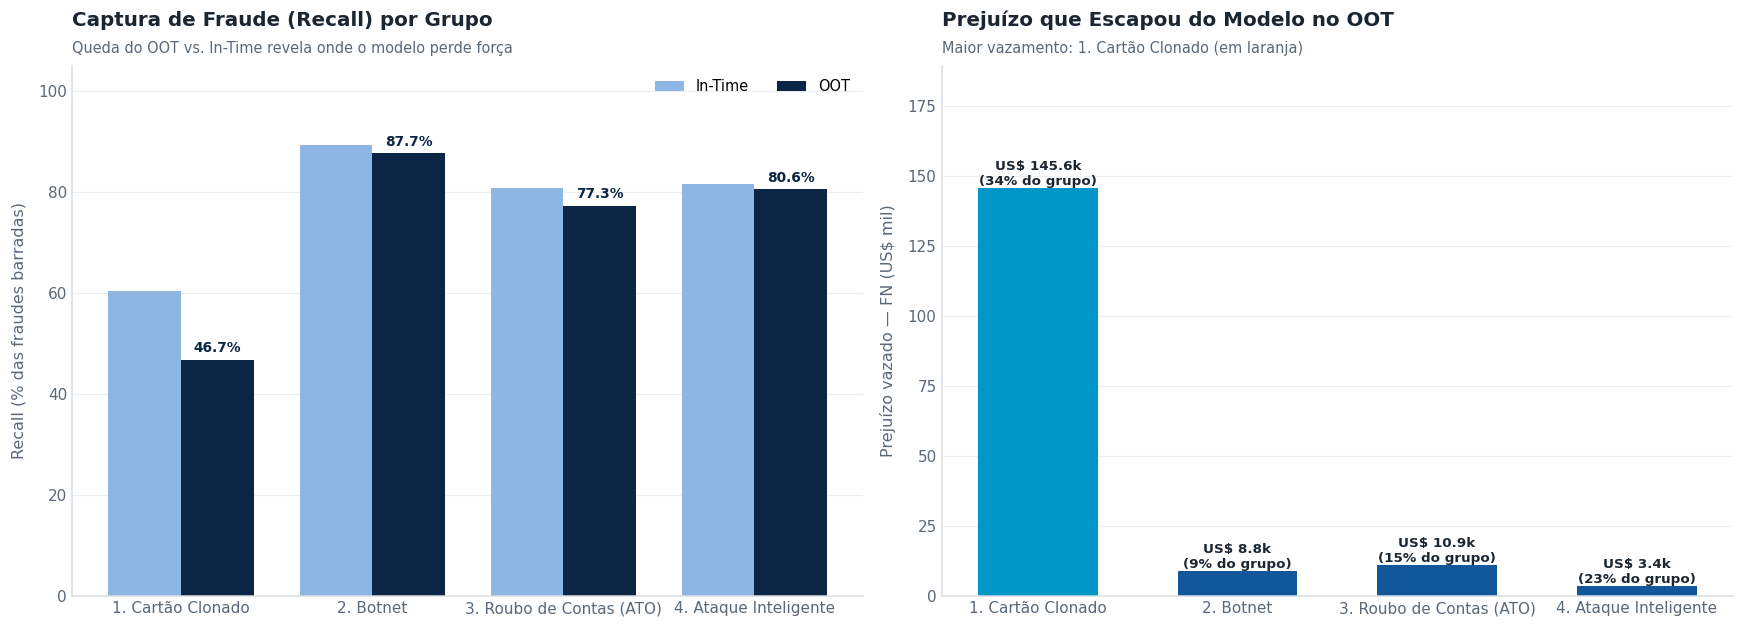

Grupo,Janela,Fraudes,Recall_%,Prejuizo_Total_USD,Prejuizo_Evitado_USD,Prejuizo_Vazado_USD,%_Vazado_USD,Ticket_Medio_USD,Score_Mediano,%_do_Vazamento_da_Janela
1. Cartão Clonado,In-Time,"7,429",60.5%,"$ 1,648,702","$ 1,185,772","$ 462,931",28.1%,$ 221.93,0.5448,84.8%
1. Cartão Clonado,OOT,"1,844",46.7%,"$ 428,722","$ 283,133","$ 145,589",34.0%,$ 232.50,0.4166,86.3%
2. Botnet,In-Time,"6,488",89.3%,"$ 347,679","$ 316,139","$ 31,541",9.1%,$ 53.59,0.9396,5.8%
2. Botnet,OOT,"1,733",87.7%,"$ 94,182","$ 85,369","$ 8,813",9.4%,$ 54.35,0.9195,5.2%
3. Roubo de Contas (ATO),In-Time,"2,051",80.9%,"$ 382,424","$ 341,926","$ 40,499",10.6%,$ 186.46,0.8816,7.4%
3. Roubo de Contas (ATO),OOT,384,77.3%,"$ 72,067","$ 61,203","$ 10,863",15.1%,$ 187.67,0.7831,6.4%
4. Ataque Inteligente,In-Time,631,81.6%,"$ 95,105","$ 83,865","$ 11,239",11.8%,$ 150.72,0.9132,2.1%
4. Ataque Inteligente,OOT,103,80.6%,"$ 14,963","$ 11,567","$ 3,396",22.7%,$ 145.27,0.8332,2.0%


In [20]:
# ==============================================================================
# 8.2a RECALL E PREJUÍZO VAZADO POR GRUPO — IN-TIME x OOT
# ==============================================================================
df_grupos = avaliar_modelo_por_grupo(df_fraudes, col_grupo='grupo', ordem=ORDEM_GRUPOS)
plot_recall_grupos_janelas(df_grupos, ordem=ORDEM_GRUPOS, filepath=fig_path('04_13_recall_vazamento_grupos.png'))

display(df_grupos.style.format({
    'Fraudes': '{:,.0f}', 'Recall_%': '{:.1f}%', 'Prejuizo_Total_USD': '$ {:,.0f}', 'Prejuizo_Evitado_USD': '$ {:,.0f}',
    'Prejuizo_Vazado_USD': '$ {:,.0f}', '%_Vazado_USD': '{:.1f}%', 'Ticket_Medio_USD': '$ {:,.2f}',
    'Score_Mediano': '{:.4f}', '%_do_Vazamento_da_Janela': '{:.1f}%',
}).hide(axis='index'))
df_grupos.to_csv(DIR_METRICAS / 'avaliacao_modelo_por_grupo.csv', index=False)

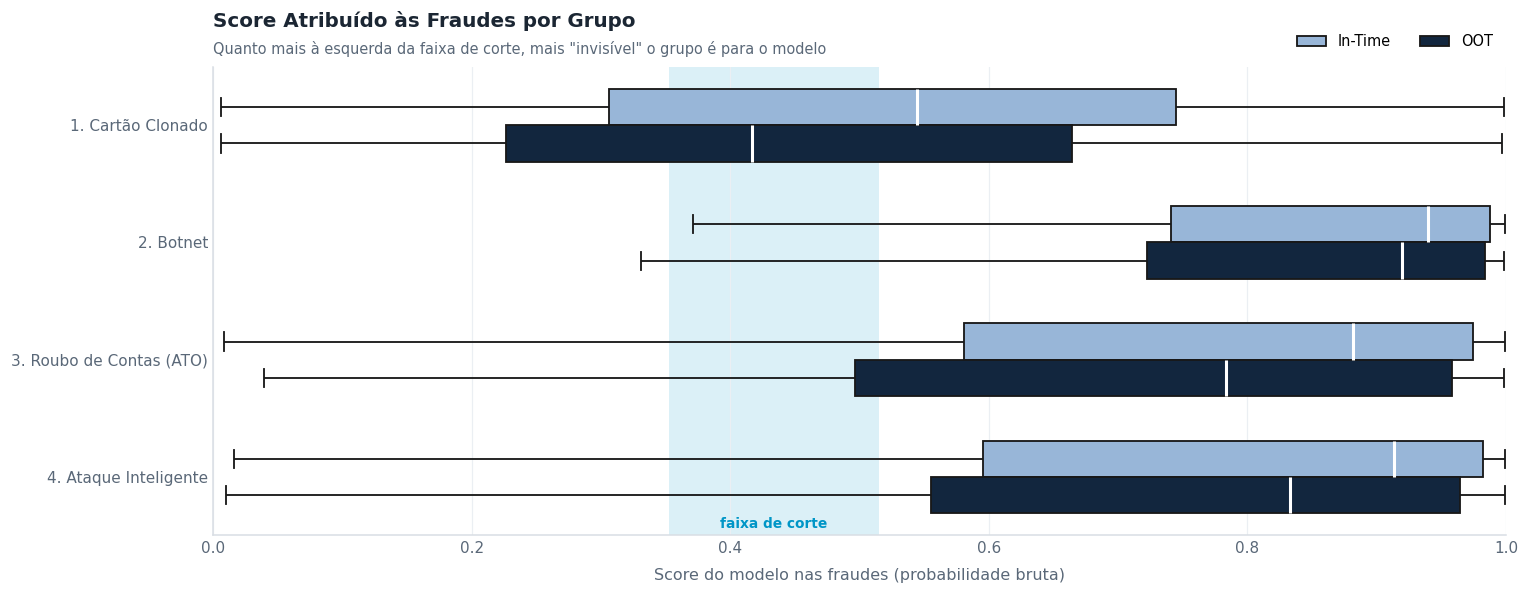

In [21]:
# ==============================================================================
# 8.2b DISTRIBUIÇÃO DO SCORE DAS FRAUDES POR GRUPO
# ==============================================================================
plot_score_fraudes_por_grupo(df_fraudes, col_grupo='grupo', ordem=ORDEM_GRUPOS,
                             faixa_corte=FAIXA_CORTE_RAW, filepath=fig_path('04_14_score_fraudes_grupos.png'))

> **Comportamento do Modelo por Arquétipo e Impacto Financeiro (In-Time vs. OOT)**
>
> O modelo demonstra alta eficiência em ataques de volumetria e alta velocidade, mas perde força no principal grupo financeiro **(Cartão Clonado)**. Veja como o comportamento se desenha:
>
> *   **1. Cartão Clonado (O Ponto de Atenção):**
>     *   **Comportamento:** O Recall cai de `60,5%` (In-Time) para **`46,7%` (OOT)**. O gráfico de score mostra o motivo: a mediana das fraudes no OOT recuou de `0,5448` para **`0,4166`**, dentro da faixa de corte (`0,3529 – 0,5149`), então mais da metade das fraudes do grupo fica abaixo do corte. O modelo passou a achar que essas transações parecem mais "legítimas".
>     *   **Impacto:** Vazamento de **`US$ 145,6 mil`** no OOT, ou **`86,3%`** de todo o chargeback da janela.
>
> `OBS = Esse grupo opera sem registro de dispositivo e sem picos de velocidade, o que o torna mais difícil de separar por padrões automáticos como os de botnets.`
>
>
> *   **2. Botnet (Boa Estabilidade):**
>     *   **Comportamento:** Altamente estável. O Recall mantém-se alto em **`87,7%`** (contra `89,3%` no In-Time). O score mediano (`0,9195`) está muito acima da faixa de corte, demonstrando que o modelo "não perdoa" bots.
>
>     *   **Impacto:** Vazamento baixo de **`US$ 8,8 mil`** no OOT.
>
> *   **3. Roubo de Contas / ATO :**
>     *   **Comportamento:** Recall cai de `80,9%` para **`77,3%`**. O score mediano recua de `0,88` para `0,78`, mas ainda permanece `confortavelmente na zona de bloqueio`.
>     *   **Impacto:** Vazamento controlado de **`US$ 10,9 mil`** no OOT.
>
> *   **4. Ataque Inteligente:**
>     *   **Comportamento:** O Recall praticamente se mantém (`81,6%` → **`80,6%`**), com score mediano de `0,8332` (ainda bem acima da faixa de corte).
>     *   **Impacto:** Menor vazamento absoluto entre os grupos, de apenas **`US$ 3,4 mil`** no OOT (com só `103` fraudes na janela).
>
> **Conclusão Estratégica:**
> **O modelo é forte contra automação e volumetria (Botnet), ATO e Ataque Inteligente**, mas perde captura no `Cartão Clonado`: o problema está no **score** desse grupo (mediana caindo para o meio da faixa de corte), e não na regra de threshold, que já é a mais rigorosa justamente para tickets altos.

---
## 9.0 Exportação das Métricas de Monitoramento (MLOps)

- Relatorios de monitoramente em `artifacts/monitoramento_oot.json` 

- **Discriminação de grupamentos, regra de decisão, financeiro, drift (score e features), estabilidade semanal e desempenho por grupo.**

In [22]:
# ==============================================================================
# 9.0 EXPORTAÇÃO DAS MÉTRICAS DE MONITORAMENTO CONTÍNUO
# ==============================================================================

def _limpo(obj):
    # Converte tipos numpy/pandas em tipos nativos JSON
    return json.loads(pd.Series([obj]).to_json(orient='records', force_ascii=False))[0]

# Estabilidade dos motores de decisão: Spearman entre os rankings de |SHAP| In-Time x OOT
_shap_m = rank_shap_oot[['Feature', 'SHAP_medio_abs']].merge(
    rank_shap_it[['Feature', 'SHAP_medio_abs']], on='Feature', suffixes=('_OOT', '_InTime'))
spearman_shap = float(spearmanr(_shap_m['SHAP_medio_abs_InTime'], _shap_m['SHAP_medio_abs_OOT']).correlation)

# Grupo que mais vaza prejuízo (US$) no OOT
_arq_oot = df_grupos[df_grupos['Janela'] == 'OOT']
pior_grupo = _arq_oot.loc[_arq_oot['Prejuizo_Vazado_USD'].idxmax()]

monitoramento = {
    'timestamp_avaliacao': datetime.now().isoformat(timespec='seconds'),
    'modelo': artefato['nome_modelo'],
    'hash_artefato': hash_artefato,
    'total_features': len(FEATURES),
    'regra_decisao': REGRA,
    'treino_escorado_oof': bool(USAR_OOF_TREINO),
    'metricas_por_base': {b: df_metricas[b].to_dict() for b in bases_avaliacao},
    'delta_oot_vs_in_time': df_metricas['Δ (OOT − In-Time)'].dropna().to_dict(),
    'separacao': {'ks_in_time': ks_it, 'ks_oot': ks_oot, 'monotonico_oot': monotonico_oot,
                  'lift_decil10_oot': float(top['lift']), 'captura_decil10_oot_pct': float(top['captura_fraudes_acum_pct'])},
    'drift': {
        'taxa_fraude_media': medias_taxa,
        'qui2_in_time_vs_oot': chi2_janelas,
        'psi_score': psi_score, 'status_psi_score': 'Estável' if psi_score < 0.10 else ('Alerta' if psi_score < 0.25 else 'Crítico'),
        'ks_shift_score': float(ks_shift.statistic),
        'psi_features': df_psi_features.set_index('Feature')['PSI'].to_dict(),
        'top_risco_drift': df_drift_risco.head(10)[['Feature', 'PSI', 'Risco_Drift']].to_dict(orient='records'),
    },
    'shap': {'spearman_in_time_vs_oot': spearman_shap,
             'top15_oot': rank_shap_oot.head(15)[['Feature', 'SHAP_medio_abs']].to_dict(orient='records')},
    'estabilidade_temporal': {'gini_medio': medias_gini, 'piso_gini': PISO_GINI, 'semanas_oot_abaixo_piso': semanas_abaixo,
                              'tendencia_gini_oot_semana': tendencia_oot,
                              'serie_semanal': df_temporal[['semana', 'Particao', 'Taxa_Fraude_%', 'GINI', 'Recall_%']].to_dict(orient='records')},
    'grupos': {'por_grupo': df_grupos.astype({'Grupo': str}).to_dict(orient='records'),
               'pior_grupo_oot': str(pior_grupo['Grupo']),
               'pior_grupo_oot_vazamento_usd': float(pior_grupo['Prejuizo_Vazado_USD'])},
}

caminho_monitoramento = dir_artifacts / 'monitoramento_oot.json'
with open(caminho_monitoramento, 'w', encoding='utf-8') as f:
    json.dump(_limpo(monitoramento), f, indent=2, ensure_ascii=False)

print(f"[MLOps] Métricas de monitoramento exportadas: {caminho_monitoramento.relative_to(PROJECT_ROOT)}")
print(f"[MLOps] CSVs em: {DIR_METRICAS.relative_to(PROJECT_ROOT)} "
      f"({', '.join(sorted(p.name for p in DIR_METRICAS.glob('avaliacao_*.csv')))})")

[MLOps] Métricas de monitoramento exportadas: artifacts/monitoramento_oot.json
[MLOps] CSVs em: reports/metrics (avaliacao_metricas_in_time_vs_oot.csv, avaliacao_metricas_semanais.csv, avaliacao_modelo_por_grupo.csv, avaliacao_psi_features.csv)


__---__
## 10.0 Conclusões


### 10.1 Resultados

**Resultados:**

| Métrica | Validação (`In-Time`) | Consolidado `In-Time` | **`OOT` (Holdout Temporal)** | **Δ (`OOT − In-Time`)** | Diagnóstico Técnico e de Negócio |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **GINI** | `0,8094` | `0,7859` | **`0,7472`** | `-0,0388` (`-4,9%`) | Queda moderada; mantém bom poder discriminante (`~0,75`) |
| **ROC-AUC** | `0,9047` | `0,8930` | **`0,8736`** | `-0,0194` | Ordenação global de risco preservada fora da janela temporal |
| **KS** | `0,6482` | `0,6246` | **`0,5773`** | `-0,0474` (`-7,6%`) | Boa separação (`~0,58`) e escada de decis 100% monotônica |
| **PR-AUC** | `0,5099` | `0,4401` | **`0,4204`** | `-0,0197` | Alta precisão relativa sob desbalanceamento severo (`3,44%` de fraude) |
| **Recall (Regra Dinâmica)** | `75,02%` | `75,10%` | **`67,96%`** | `-7,14 p.p.` | Retração concentrada no grupo *Cartão Clonado* (`46,7%`) |
| **Precision** | `20,83%` | `17,24%` | **`16,38%`** | `-0,87 p.p.` | Leve queda frente ao In-Time; `-4,45 p.p.` frente à Validação |
| **Aceitação Geral / Legítimas** | `85,94%` / `88,41%` | `84,70%` / `86,88%` | **`85,72%` / `87,63%`** | `+1,02 p.p.` / `+0,76 p.p.` | Atrito comercial estável, com leve melhora na aprovação de bons clientes |
| **Lucro Líquido Total** | `US$ 27.906` | `US$ 262.453` | **`US$ 35.861`** | `+US$ 7.955` *(vs. Val)* | Reverte prejuízo de `US$ -297.264` (sem modelo), gerando **`+US$ 333.125`** de valor |
| **Lucro por Transação** | `US$ 0,236` | `US$ 0,556` | **`US$ 0,304`** | `+US$ 0,068` *(vs. Val)* | Rentabilidade unitária no `OOT` acima da `Validação` (`+29%`) |

---

### 10.2 Funcionamento, Estabilidade e Métricas Financeiras

*   **Funcionamento e Interpretabilidade (`SHAP` e Decis):** O modelo opera com coerência entre `In-Time` e `OOT` (Spearman dos rankings de |SHAP| = `0,934`), guiado por sinais de valor, tempo, raridade da faixa do cartão e velocidade (`V70`, `TransactionAmt`, `delta_D2`, `card1_freq`, `delta_D15`, `vel_C5`, `vel_C2`). No `OOT`, o **Decil 10 concentra `61,0%` de todas as fraudes com `Lift de 6,1x`** (`75,4%` nos dois primeiros decis), sem nenhuma inversão na escada de risco.
*   **Estabilidade Populacional e Temporal (`PSI` e `GINI` Semanal):**
    *   **Score e Target:** Taxa de fraude estável (`3,51%` $\rightarrow$ `3,44%`, $V$ de Cramér `= 0,0016`) e **`PSI do Score = 0,0028` (`< 0,10`, Estável)**.
    *   **Features:** Das `30` variáveis do modelo, **`29` permaneceram Estáveis**, **`1` entrou em Alerta** (`match_cont_F = 0,127`, rank 24 no SHAP) e **nenhuma (`0`) atingiu nível Crítico (`PSI ≥ 0,25`)**.
    *   **Série Semanal:** O `GINI` semanal no `OOT` manteve média de `0,7474`, com **zero semanas abaixo do piso de tolerância (`0,7087`)** e tendência levemente positiva (`+0,0042/semana`). As seis semanas deram lucro (de `US$ 1,3k` a `US$ 11,6k`/semana).
*   **Desempenho Financeiro e de Negócio:** No `OOT` (`118.108` transações), a regra dinâmica evitou **`US$ 441.272` em fraudes (`2.762` VPs, `72,3%` do valor fraudado)**, aprovou `87,63%` das legítimas e entregou **`US$ 35.861` de lucro líquido (`US$ 0,304/tx`)**, acima da `Validação` (`US$ 27.906` / `US$ 0,236/tx`).

---

### 10.3 Avaliação Crítica: Pontos Positivos vs. Pontos a Melhorar

#### Pontos Positivos (Fortalezas do Modelo)
1.  **Generalização Financeira no Futuro (`OOT`):** Mesmo em dados de meses futuros, o modelo sustenta lucro líquido (`US$ 35.861`, acima da Validação) e aprova quase `88%` dos clientes legítimos (`87,63%`), com volume de bloqueio estável (`14,28%`).
2.  **Blindagem contra Fraudes Automatizadas e de Velocidade:** Boa retenção de performance contra **`2. Botnet` (`Recall = 87,7%` no `OOT`, score mediano `0,9195`)**, **`3. Roubo de Contas / ATO` (`Recall = 77,3%`, score mediano `0,7831`)** e **`4. Ataque Inteligente` (`Recall = 80,6%`, score mediano `0,8332`)** — juntos, esses três grupos somam apenas `13,6%` do vazamento financeiro no `OOT`.
3.  **Baixa Sensibilidade a Feature Drift:** A poda para `30` features manteve o Top 10 do `SHAP` livre de drift relevante (`PSI < 0,05` em todas as variáveis líderes); a única feature em Alerta (`match_cont_F`) tem baixa importância no modelo (rank 24).

#### Pontos de Atenção e Oportunidades de Melhoria
1.  **Vulnerabilidade no Grupo `1. Cartão Clonado` (Principal Gargalo Financeiro):**
    *   O `Recall` desse grupo caiu de `60,5%` (`In-Time`) para **`46,7%` (`OOT`)**, pois o score mediano recuou para **`0,4166`**, no meio da faixa de corte (`[0,3529 – 0,5149]`).
    *   Por operar sem registro de dispositivo e sem picos de velocidade, e ter **ticket médio elevado (`US$ 232,50`)**, esse único grupo responde por **`86,3%` de todo o chargeback vazado no `OOT` (`US$ 145.589` de `US$ 168.662`)**. É também o grupo que estava **crescendo** no fim do Treino (`03`, Seção 6.4).
2.  **Perda de Discriminação e Sub-calibração no `OOT`:**
    *   O GINI caiu de `0,8094` (Validação) para `0,7472` (OOT), e a probabilidade calibrada média ficou em `2,94%` frente a uma taxa real de `3,44%` (`-14,6%`). A queda de `-7,14 p.p.` no `Recall` vem principalmente da **perda de discriminação** (concentrada no *Cartão Clonado*), já que na Validação a sub-calibração era até maior (`-20,8%`) com Recall de `75,0%`.
    *   **Modelo enxuto:** o `LGBM_Max` (125 features) teve lucro maior na Validação (`02`, Seção 7.3); vale testá-lo no OOT para confirmar se a parcimônia do `LGBM_Otimizado` compensa.
3.  **Próximos Passos Recomendados para Evolução:**
    *   **Features de Perfil de Gasto Individual (`Z-Score` de Ticket por Cartão):** criar razões entre `TransactionAmt` e a média/máximo histórico do próprio cartão (`card1 + card2 + addr1`), calculadas **apenas com transações anteriores** a cada compra, para destacar compras atípicas de *Cartão Clonado* mesmo quando a velocidade (`vel_C*`) é baixa.
    *   **Recalibração Periódica (`Janela Deslizante`):** atualizar apenas o calibrador isotônico com a safra mais recente (mantendo a árvore fixa) quando o erro relativo de calibração ultrapassar `15%`.
    *   **Monitoramento:** acompanhar semanalmente o PSI de `match_cont_F` e `delta_D15`, a cobertura dos blocos D/M e o Recall do grupo *Cartão Clonado*.